# Fase 3 — Modelado avanzado, clustering, optimización e interpretabilidad

| | |
|---|---|
| **Universidad** | Universidad de La Salle |
| **Facultad** | Facultad de Ingeniería |
| **Asignatura** | Ciencia de Datos — Maestría en Inteligencia Artificial |
| **Docente** | Fabián Camilo Castro Riveros |
| **Autores** | Tony Yu<br>Luis Rodríguez<br>Maydda Rodríguez |
| **Fase** | Fase 3 (25%) |
| **Fecha de entrega** | Domingo 22 de noviembre de 2026 |

**Informe asociado:** *Entregable3_Informe_APA.docx* (normas APA, 7.ª edición). El cuaderno y el informe usan las mismas cifras: el cuaderno las exporta a `modelos/resultados_fase3.json`.

## Resumen

Este cuaderno entrena, ajusta y compara los modelos avanzados del proyecto sobre las mismas particiones 70/15/15 de la Fase 2: regresión del volumen horario de tráfico, clasificación de su nivel (bajo, medio, alto), un perceptrón multicapa en PyTorch y una segmentación no supervisada de las horas. Los hiperparámetros se buscan con validación cruzada de 5 pliegues dentro de entrenamiento y el conjunto de prueba se abre una sola vez, con la selección ya fijada. En regresión, XGBoost reduce el RMSE de prueba de 783 a 364 vehículos por hora (*R*² de 0,966 frente a 0,844 del modelo base), con una mejora de 0,123 en *R*² (IC del 95 %: 0,116 a 0,130). En clasificación, XGBoost alcanza un F1 macro de 0,927 y un AUC-ROC de 0,986 (base: 0,896 y 0,972). El MLP queda cerca (*R*² de 0,962 y F1 de 0,922), sin superar a los árboles. El K-means con K = 5 (codo y silueta coinciden) y el jerárquico dan una segmentación estable pero de estructura débil a moderada (silueta de 0,333) dominada por el calendario. SHAP y la importancia por permutación coinciden: la hora explica el 70 % de la atribución, el día de la semana el 19 % y el clima menos del 4 %.

*Palabras clave:* XGBoost, redes neuronales, clustering, SHAP, sobreajuste, interpretabilidad.

## Estructura del repositorio y reproducibilidad

```
repositorio/
├── data/processed/            ← train.csv, val.csv, test.csv (entrada de esta fase; salida de la Fase 2)
├── models/                    ← resultados_fase2.json (entrada) · modelos finales, clusters y resultados_fase3.json (salida)
├── notebooks/                 ← 01_eda · 02_preprocesamiento · 03_modelado (este cuaderno)
├── src/                       ← módulos reutilizables que usa el dashboard
├── dashboard/                 ← aplicación Streamlit (Fase 4)
└── requirements.txt           ← versiones exactas del entorno
```

**Cómo ejecutarlo:** crear un entorno virtual limpio, instalar `requirements.txt` y ejecutar *Kernel → Restart & Run All* desde la carpeta `notebooks/`. **En Google Colab** ejecute antes `!pip install shap xgboost` (torch y scikit-learn ya vienen instalados) y suba `train.csv`, `val.csv` y `test.csv` a `/content`; si no están, el cuaderno se detiene con un mensaje claro y no simula datos. Requiere haber ejecutado antes el cuaderno de la Fase 2 (o usar los CSV ya incluidos en `data/processed/`). La semilla global es 42 y todo el cuaderno se ejecuta en unos 15 minutos con 2 núcleos de CPU, sin GPU.

**Protocolo contra la fuga de datos.** (1) Los hiperparámetros se buscan con validación cruzada *solo dentro de entrenamiento*, y el preprocesamiento está dentro del `Pipeline`, de modo que se reajusta en cada pliegue. (2) El conjunto de validación sirve para comparar modelos y para la parada temprana del MLP. (3) La selección de los modelos finales queda fijada **antes** de mirar el conjunto de prueba, y este se evalúa **una sola vez** (sección 8).

## 1. Configuración, entorno y datos

Se cargan las particiones 70/15/15 estratificadas creadas en la Fase 2, de modo que todos los modelos se comparan exactamente con los mismos datos y con el mismo modelo base de la fase anterior. La etiqueta `nivel_trafico` usa los umbrales fijos de la Fase 2: bajo (< 1.500), medio (1.500 a 4.499) y alto (≥ 4.500 vehículos por hora).

In [1]:
# ======================================================================
# Fase 3 · Modelado avanzado, clustering, optimización e interpretabilidad
# Semilla global: 42. Entorno: ver la celda de versiones.
# ======================================================================
import copy
import json
import sys
import warnings
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.base import clone
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, adjusted_rand_score, f1_score, mean_absolute_error,
    mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score, silhouette_score,
)
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
SEMILLA = 42
np.random.seed(SEMILLA)
torch.set_num_threads(2)

# --- Formato numérico español (1.234,567) para tablas y ejes ---
def es(x, dec=3):
    return f"{x:,.{dec}f}".replace(",", "_").replace(".", ",").replace("_", ".")

pd.set_option("display.float_format", es)

def ejes_es(fig):
    '''Aplica el formato español a los ejes numéricos de una figura.'''
    def fmt(v, _):
        txt = es(v, 2)
        return txt.rstrip("0").rstrip(",") if "," in txt else txt
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            if isinstance(eje.get_major_formatter(), ScalarFormatter):
                eje.set_major_formatter(FuncFormatter(fmt))

R = {}                      # resultados que se exportan a JSON (el informe usa estas cifras)
def a_json(df):
    return json.loads(df.reset_index().to_json(orient="records"))

Path("../models").mkdir(exist_ok=True)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Entorno y versiones

In [2]:
paquetes = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib", "ipykernel",
            "torch", "shap", "xgboost"]
versiones = {p: version(p) for p in paquetes}
print("Python", sys.version.split()[0])
print(versiones)
_ = Path("../docs/entorno_fase_3.txt").write_text("\n".join(f"{p}=={v}" for p, v in versiones.items()) + "\n")
R["entorno"] = {"python": sys.version.split()[0], **versiones}

Python 3.13.18
{'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0', 'ipykernel': '7.4.0', 'torch': '2.15.0', 'shap': '0.54.1', 'xgboost': '3.4.1'}


In [3]:
# --- Ubicación de los datos de la Fase 2 (train.csv, val.csv y test.csv) ---
# Se busca en este orden: carpeta del repositorio, raíz de Colab y Google Drive. Si no están, el cuaderno se DETIENE:
# nunca se simulan datos, porque unos resultados sobre datos inventados no sirven para el informe.
NOMBRES_CSV = ("train", "val", "test")
CANDIDATAS = [Path("../data/processed"), Path("../fase_2/data"), Path("fase_2/data"), Path("/content"),
              Path("/content/drive/MyDrive/fase_2/data"), Path("/content/drive/MyDrive/data")]
hay_datos = lambda r: all((r / f"{n}.csv").exists() for n in NOMBRES_CSV)
RUTA = next((r for r in CANDIDATAS if hay_datos(r)), None)

if RUTA is None:                                   # en Colab, intentar montar Google Drive (opcional)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        RUTA = next((r for r in CANDIDATAS if hay_datos(r)), None)
    except ImportError:
        pass
if RUTA is None:
    raise FileNotFoundError("No se encontraron train.csv, val.csv y test.csv de la Fase 2. Ejecute primero el cuaderno de la Fase 2 "
                            "y deje esos archivos en ../data/processed (o súbalos a /content o a MyDrive/fase_2/data).")
print("✔ Datos reales de la Fase 2 cargados desde:", RUTA.resolve())

train, val, test = [pd.read_csv(RUTA / f"{n}.csv") for n in NOMBRES_CSV]
for d in (train, val, test):
    assert d.isna().sum().sum() == 0, "las particiones de la Fase 2 no deben tener faltantes"

ORDEN = ["bajo", "medio", "alto"]
COD = {n: i for i, n in enumerate(ORDEN)}
LOG, NUM, CAT, BIN = ["rain_1h", "snow_1h"], ["temp", "clouds_all"], ["weather_main", "hora", "dia_semana", "mes"], ["es_festivo"]
ENTRADAS = LOG + NUM + CAT + BIN

X_train, X_val, X_test = train[ENTRADAS], val[ENTRADAS], test[ENTRADAS]
y_train_reg, y_val_reg, y_test_reg = (d["traffic_volume"].values for d in (train, val, test))
y_train_clf, y_val_clf, y_test_clf = (d["nivel_trafico"].map(COD).values for d in (train, val, test))

# Coherencia con la Fase 2 (solo lectura: este cuaderno nunca modifica los archivos de la Fase 2)
J2 = next((j for j in (Path("../models/resultados_fase2.json"), RUTA.parent / "modelos" / "resultados_fase2.json", RUTA / "resultados_fase2.json", Path("resultados_fase2.json")) if j.exists()), Path("no_existe.json"))
if J2.exists():
    p2 = json.loads(J2.read_text())["particion"]
    assert [r["filas"] for r in p2] == [len(train), len(val), len(test)], "las particiones no coinciden con la Fase 2"
    print("✔ Tamaños coinciden con", J2)
else:
    print("Aviso: no se encontró resultados_fase2.json; no se verifica la coincidencia con la Fase 2.")
assert (train["nivel_trafico"] == pd.cut(train["traffic_volume"], [-np.inf, 1500, 4500, np.inf], right=False, labels=ORDEN)).all()

R["particion"] = {"train": len(train), "val": len(val), "test": len(test)}
print(R["particion"])
print(train["nivel_trafico"].value_counts(normalize=True).reindex(ORDEN).round(3).to_dict())

✔ Datos reales de la Fase 2 cargados desde: /home/claude/repo/data/processed
✔ Tamaños coinciden con ../models/resultados_fase2.json
{'train': 28402, 'val': 6086, 'test': 6087}
{'bajo': 0.272, 'medio': 0.37, 'alto': 0.358}


### Preprocesamiento y métricas

Se reutiliza el preprocesador de la Fase 2 (log(1 + *x*) y estandarización para lluvia y nieve, estandarización para temperatura y nubosidad, *one-hot* para las categóricas y festivo sin cambios), que alimenta a los modelos lineales y al MLP. Los modelos de árboles no necesitan escalamiento ni *one-hot* del calendario, así que reciben `hora`, `dia_semana` y `mes` como números: con ellos un árbol puede partir directamente en «hora ≥ 15», y SHAP atribuye el efecto a una sola variable de calendario en lugar de a 43 columnas indicadoras. Ambos preprocesadores se ajustan dentro del `Pipeline`, por lo que solo ven los datos de entrenamiento de cada pliegue.

In [4]:
preprocesador = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), LOG),
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), CAT),
    ("bin", "passthrough", BIN),
])
pre_arbol = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), ["weather_main"]),
    ("num", "passthrough", ["rain_1h", "snow_1h", "temp", "clouds_all", "hora", "dia_semana", "mes", "es_festivo"]),
], verbose_feature_names_out=False)

def met_reg(y, p):
    return {"R²": r2_score(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "MAE": mean_absolute_error(y, p)}

def met_clf(y, pred, proba):
    return {"Accuracy": accuracy_score(y, pred),
            "Precisión macro": precision_score(y, pred, average="macro"),
            "Recall macro": recall_score(y, pred, average="macro"),
            "F1 macro": f1_score(y, pred, average="macro"),
            "AUC-ROC": roc_auc_score(y, proba, multi_class="ovr", average="macro")}

CV_REG = KFold(5, shuffle=True, random_state=SEMILLA)
CV_CLF = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)

# --- Modelos base de la Fase 2, reentrenados para comparar con las mismas particiones ---
base_reg = Pipeline([("pre", clone(preprocesador)), ("m", LinearRegression())]).fit(X_train, y_train_reg)
base_clf = Pipeline([("pre", clone(preprocesador)), ("m", LogisticRegression(max_iter=1000))]).fit(X_train, y_train_clf)
mb_r, mb_c = met_reg(y_val_reg, base_reg.predict(X_val)), met_clf(y_val_clf, base_clf.predict(X_val), base_clf.predict_proba(X_val))
print("Baseline de la Fase 2 (validación):", {k: round(v, 4) for k, v in {**mb_r, **mb_c}.items()})
if J2.exists():
    datos_j2 = json.loads(J2.read_text())
    if "baseline" in datos_j2:
        j2 = datos_j2["baseline"]
        assert abs(mb_r["R²"] - j2["reg"][1]["R²"]) < 1e-6 and abs(mb_c["F1 macro"] - j2["clf"][1]["F1 macro"]) < 1e-6, "el baseline no coincide con la Fase 2"
        print("✔ coincide con los resultados guardados en la Fase 2")
    else:
        print("Aviso: el JSON de la Fase 2 no trae 'baseline'; no se verifica (no se modifica el archivo).")
R["baseline_val"] = {"reg": mb_r, "clf": mb_c}

Baseline de la Fase 2 (validación): {'R²': 0.8383, 'RMSE': 800.055, 'MAE': 582.8013, 'Accuracy': 0.8876, 'Precisión macro': 0.8912, 'Recall macro': 0.8919, 'F1 macro': 0.8911, 'AUC-ROC': 0.9716}
✔ coincide con los resultados guardados en la Fase 2


## 2. Regresión del volumen de tráfico

La Fase 2 mostró que el modelo lineal se equivoca de forma sistemática en las horas pico, porque no captura la **interacción** entre hora y tipo de día (sección 8 de la Fase 2). Se comparan por eso dos familias que atacan esa limitación de formas distintas, ambas tuneadas con validación cruzada de 5 pliegues *dentro de entrenamiento*:

1. **Ridge con interacciones** (regresión lineal regularizada). Se añaden los productos por pares de las variables transformadas (`PolynomialFeatures(2, interaction_only=True)`) y la penalización L2 controla la multicolinealidad y el sobreajuste que esas 1.711 columnas introducen.
2. **XGBoost** (ensamble de árboles con *boosting*), que aprende interacciones y no linealidades sin que se las pidamos. Se explora el espacio de hiperparámetros con búsqueda aleatoria (12 combinaciones × 5 pliegues).

El MLP en PyTorch se entrena en la sección 4. La métrica de selección es el RMSE, que penaliza más los errores grandes en horas pico.

In [5]:
# --- 2.1 Ridge con interacciones ---
ridge_pipe = Pipeline([("pre", clone(preprocesador)),
                       ("int", PolynomialFeatures(2, interaction_only=True, include_bias=False)),
                       ("m", Ridge())])
busq_ridge = GridSearchCV(ridge_pipe, {"m__alpha": [0.01, 0.1, 1, 10, 100, 300, 1000, 3000]}, cv=CV_REG,
                          scoring="neg_root_mean_squared_error", n_jobs=2, return_train_score=True).fit(X_train, y_train_reg)
cv_ridge = pd.DataFrame(busq_ridge.cv_results_)[["param_m__alpha", "mean_train_score", "mean_test_score", "std_test_score"]]
cv_ridge.columns = ["alpha", "RMSE entrenamiento (CV)", "RMSE validación cruzada", "desv. est."]
cv_ridge[["RMSE entrenamiento (CV)", "RMSE validación cruzada"]] *= -1
cv_ridge["alpha"] = cv_ridge["alpha"].astype(float)
display(cv_ridge)
reg_ridge = busq_ridge.best_estimator_
print("Mejor alpha:", busq_ridge.best_params_, "| columnas tras interacciones:", reg_ridge[:-1].transform(X_train.head(2)).shape[1])
R["ridge"] = {"mejor": busq_ridge.best_params_, "cv": a_json(cv_ridge), "n_cols": int(reg_ridge[:-1].transform(X_train.head(2)).shape[1])}

,alpha,RMSE entrenamiento (CV),RMSE validación cruzada,desv. est.
0,"0,010","387,517","409,810","13,530"
1,"0,100","387,519","409,764","13,530"
2,"1,000","387,680","409,516","13,524"
3,"10,000","395,478","415,261","13,714"
4,"100,000","519,769","534,340","11,646"
5,"300,000","698,294","709,901","9,476"
6,"1.000,000","1.023,642","1.032,391","7,389"
7,"3.000,000","1.406,678","1.412,702","5,376"


Mejor alpha: {'m__alpha': 1} | columnas tras interacciones: 1711


In [6]:
# --- 2.2 XGBoost regresor con búsqueda aleatoria ---
dist_xgb = {"m__n_estimators": [200, 400, 600], "m__max_depth": [3, 4, 6, 8], "m__learning_rate": [0.03, 0.05, 0.1],
            "m__subsample": [0.7, 0.85, 1.0], "m__colsample_bytree": [0.7, 0.85, 1.0],
            "m__min_child_weight": [1, 5, 10], "m__reg_lambda": [1, 5, 10]}
xgb_reg_pipe = Pipeline([("pre", clone(pre_arbol)), ("m", XGBRegressor(tree_method="hist", n_jobs=1, random_state=SEMILLA))])
busq_xgb_r = RandomizedSearchCV(xgb_reg_pipe, dist_xgb, n_iter=12, cv=CV_REG, scoring="neg_root_mean_squared_error",
                                n_jobs=2, random_state=SEMILLA, return_train_score=True).fit(X_train, y_train_reg)
cv_xgb_r = pd.DataFrame(busq_xgb_r.cv_results_).sort_values("rank_test_score").head(5)
cols = ["param_m__n_estimators", "param_m__max_depth", "param_m__learning_rate", "mean_train_score", "mean_test_score"]
cv_xgb_r = cv_xgb_r[cols].copy()
cv_xgb_r.columns = ["árboles", "profundidad", "tasa de aprend.", "RMSE entrenamiento (CV)", "RMSE validación cruzada"]
cv_xgb_r[["RMSE entrenamiento (CV)", "RMSE validación cruzada"]] *= -1
display(cv_xgb_r.reset_index(drop=True))
reg_xgb = busq_xgb_r.best_estimator_
print("Mejores hiperparámetros:", {k.replace("m__", ""): v for k, v in busq_xgb_r.best_params_.items()})
R["xgb_reg"] = {"mejor": {k.replace("m__", ""): (v.item() if hasattr(v, "item") else v) for k, v in busq_xgb_r.best_params_.items()},
                "top5": a_json(cv_xgb_r.reset_index(drop=True)), "n_combinaciones": 12, "pliegues": 5}

,árboles,profundidad,tasa de aprend.,RMSE entrenamiento (CV),RMSE validación cruzada
0,600,8,"0,030","298,379","371,156"
1,600,8,"0,030","311,526","371,602"
2,600,6,"0,100","310,979","376,470"
3,600,6,"0,050","324,081","376,481"
4,400,6,"0,030","358,545","388,203"


Mejores hiperparámetros: {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.85}


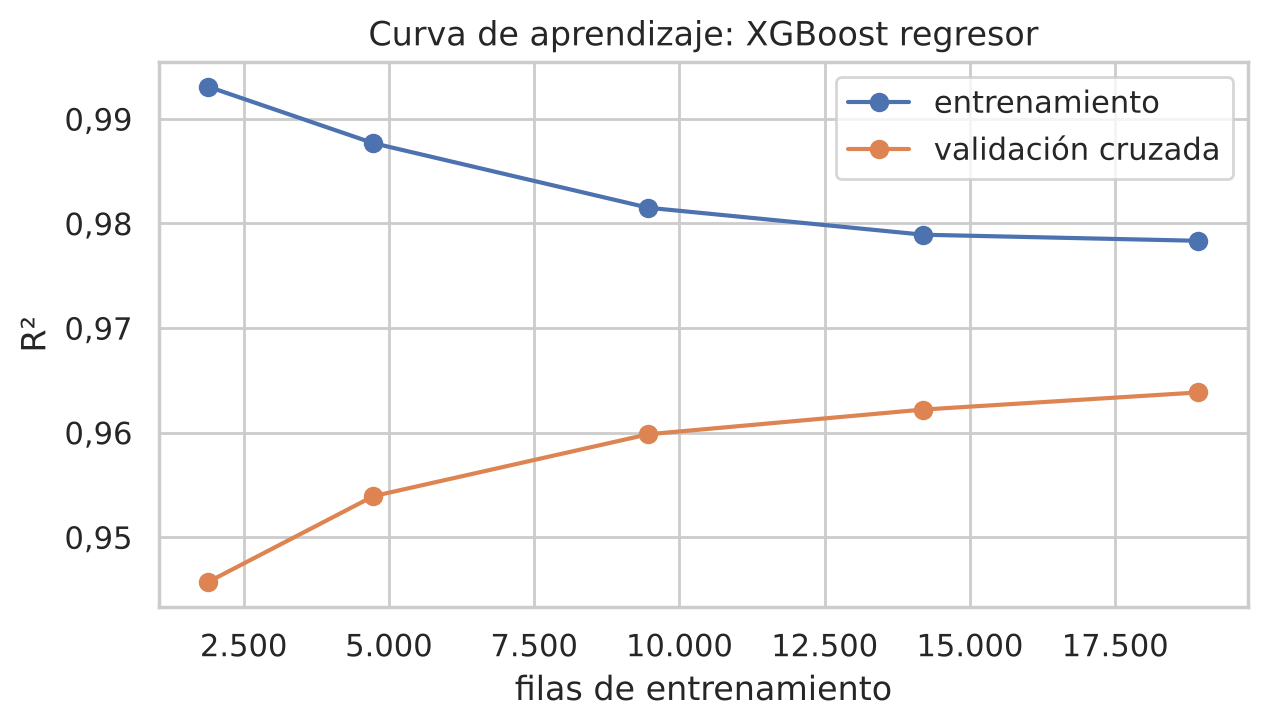

**Lectura.** Con las 18.934 filas que usa cada ajuste (dos tercios del entrenamiento, por los 3 pliegues), el R² es 0,978 en entrenamiento y 0,964 en validación cruzada (brecha de 0,015). La brecha se reduce al crecer la muestra y la validación cruzada ya solo gana 0,0016 al pasar de 14.200 a 18.934 filas: más datos ayudarían poco, y el sobreajuste es moderado y estable.

In [7]:
# --- 2.3 Curva de aprendizaje del mejor XGBoost: ¿hay sobreajuste o falta de datos? ---
tam, tr_sc, cv_sc = learning_curve(clone(reg_xgb), X_train, y_train_reg, cv=KFold(3, shuffle=True, random_state=SEMILLA),
                                   train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], scoring="r2", n_jobs=2)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(tam, tr_sc.mean(1), "o-", label="entrenamiento")
ax.plot(tam, cv_sc.mean(1), "o-", label="validación cruzada")
ax.set(xlabel="filas de entrenamiento", ylabel="R²", title="Curva de aprendizaje: XGBoost regresor")
ax.legend(); ejes_es(fig); plt.tight_layout(); plt.show()
R["curva_aprendizaje"] = {"tam": tam.tolist(), "r2_train": tr_sc.mean(1).tolist(), "r2_cv": cv_sc.mean(1).tolist()}
ganancia = cv_sc.mean(1)[-1] - cv_sc.mean(1)[-2]
display(Markdown(f"**Lectura.** Con las {es(tam[-1], 0)} filas que usa cada ajuste (dos tercios del entrenamiento, por los 3 pliegues), el R² es {es(tr_sc.mean(1)[-1])} en entrenamiento y {es(cv_sc.mean(1)[-1])} en validación cruzada "
                 f"(brecha de {es(tr_sc.mean(1)[-1] - cv_sc.mean(1)[-1])}). La brecha se reduce al crecer la muestra y la validación cruzada ya solo gana {es(ganancia, 4)} al pasar de {es(tam[-2], 0)} a {es(tam[-1], 0)} filas: "
                 "más datos ayudarían poco, y el sobreajuste es moderado y estable."))

## 3. Clasificación del nivel de tráfico

Se comparan dos algoritmos distintos —**Random Forest** (promedio de árboles decorrelacionados, *bagging*) y **XGBoost** (árboles en serie, *boosting*)— frente a la regresión logística de la Fase 2. Ambos reciben las mismas variables que el modelo base. La búsqueda aleatoria (10 combinaciones × 5 pliegues estratificados) optimiza el F1 macro, que pondera por igual las tres clases. El AUC-ROC se calcula uno-contra-resto y se promedia (macro).

In [8]:
# --- 3.1 Random Forest ---
rf_pipe = Pipeline([("pre", clone(pre_arbol)), ("m", RandomForestClassifier(n_jobs=1, random_state=SEMILLA))])
dist_rf = {"m__n_estimators": [200, 300, 500], "m__max_depth": [8, 12, 16, None], "m__min_samples_leaf": [1, 3, 5, 10],
           "m__max_features": ["sqrt", 0.5]}
busq_rf = RandomizedSearchCV(rf_pipe, dist_rf, n_iter=10, cv=CV_CLF, scoring="f1_macro", n_jobs=2,
                             random_state=SEMILLA, return_train_score=True).fit(X_train, y_train_clf)
clf_rf = busq_rf.best_estimator_

# --- 3.2 XGBoost ---
xgb_clf_pipe = Pipeline([("pre", clone(pre_arbol)), ("m", XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEMILLA))])
busq_xgb_c = RandomizedSearchCV(xgb_clf_pipe, dist_xgb, n_iter=10, cv=CV_CLF, scoring="f1_macro", n_jobs=2,
                                random_state=SEMILLA, return_train_score=True).fit(X_train, y_train_clf)
clf_xgb = busq_xgb_c.best_estimator_

limpiar = lambda d: {k.replace("m__", ""): (v.item() if hasattr(v, "item") else v) for k, v in d.items()}
print("Random Forest:", limpiar(busq_rf.best_params_), "| F1 macro CV:", es(busq_rf.best_score_, 4))
print("XGBoost      :", limpiar(busq_xgb_c.best_params_), "| F1 macro CV:", es(busq_xgb_c.best_score_, 4))
R["rf"] = {"mejor": limpiar(busq_rf.best_params_), "f1_cv": busq_rf.best_score_, "f1_train_cv": busq_rf.cv_results_["mean_train_score"][busq_rf.best_index_]}
R["xgb_clf"] = {"mejor": limpiar(busq_xgb_c.best_params_), "f1_cv": busq_xgb_c.best_score_, "f1_train_cv": busq_xgb_c.cv_results_["mean_train_score"][busq_xgb_c.best_index_]}

Random Forest: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': None} | F1 macro CV: 0,9208
XGBoost      : {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.85} | F1 macro CV: 0,9242


## 4. Perceptrón multicapa (MLP) en PyTorch

Se diseña un MLP para cada tarea: uno de regresión (pérdida MSE sobre el volumen estandarizado) y uno de clasificación (pérdida de entropía cruzada sobre los tres niveles). Las entradas son las 58 columnas del preprocesador de la Fase 2. Cada red usa capas densas con activación ReLU, *dropout* y optimizador Adam con decaimiento de pesos (L2).

**Control del sobreajuste.** (1) *Parada temprana*: se entrena hasta 120 épocas y se detiene si la pérdida de validación no mejora en 12 épocas seguidas; se conserva el estado de la mejor época. (2) *Dropout* y decaimiento de pesos. (3) La pérdida de entrenamiento se mide con la red en modo evaluación, para que sea comparable con la de validación. Se comparan cuatro configuraciones por tarea y se elige la de menor pérdida de validación; en este caso la búsqueda se hace con la partición de validación y no con validación cruzada, porque cada ajuste de una red cuesta mucho más que el de un modelo de árboles.

In [9]:
from torch.utils.data import DataLoader, TensorDataset

pre_mlp = clone(preprocesador).fit(X_train)
tens = lambda X: torch.tensor(pre_mlp.transform(X), dtype=torch.float32)
Xt_tr, Xt_va = tens(X_train), tens(X_val)
mu_y, sd_y = float(y_train_reg.mean()), float(y_train_reg.std())

def construir_mlp(n_in, n_out, ocultas, p):
    capas, d = [], n_in
    for h in ocultas:
        capas += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p)]
        d = h
    return nn.Sequential(*capas, nn.Linear(d, n_out))

def entrenar_mlp(tarea, ocultas, p, lr, wd, max_ep=120, paciencia=12, lote=256, semilla=SEMILLA):
    torch.manual_seed(semilla)
    reg = tarea == "reg"
    ytr = torch.tensor((y_train_reg - mu_y) / sd_y, dtype=torch.float32).unsqueeze(1) if reg else torch.tensor(y_train_clf, dtype=torch.long)
    yva = torch.tensor((y_val_reg - mu_y) / sd_y, dtype=torch.float32).unsqueeze(1) if reg else torch.tensor(y_val_clf, dtype=torch.long)
    modelo = construir_mlp(Xt_tr.shape[1], 1 if reg else 3, ocultas, p)
    perdida = nn.MSELoss() if reg else nn.CrossEntropyLoss()
    opt = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=wd)
    cargador = DataLoader(TensorDataset(Xt_tr, ytr), batch_size=lote, shuffle=True, generator=torch.Generator().manual_seed(semilla))
    hist, mejor, sin_mejora = [], (np.inf, None, 0), 0
    for ep in range(1, max_ep + 1):
        modelo.train()
        for xb, yb in cargador:
            opt.zero_grad()
            perdida(modelo(xb), yb).backward()
            opt.step()
        modelo.eval()
        with torch.no_grad():
            l_tr, l_va = perdida(modelo(Xt_tr), ytr).item(), perdida(modelo(Xt_va), yva).item()
        hist.append((ep, l_tr, l_va))
        if l_va < mejor[0] - 1e-5:
            mejor, sin_mejora = (l_va, copy.deepcopy(modelo.state_dict()), ep), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor[1]); modelo.eval()
    return modelo, pd.DataFrame(hist, columns=["época", "entrenamiento", "validación"]), mejor[2]

class EnvolturaMLP:
    '''Hace que una red de PyTorch se use como un estimador de scikit-learn (predict / predict_proba).'''
    def __init__(self, pre, modelo, tarea):
        self.pre, self.modelo, self.tarea = pre, modelo, tarea
    def _salida(self, X):
        self.modelo.eval()
        with torch.no_grad():
            return self.modelo(torch.tensor(self.pre.transform(X), dtype=torch.float32))
    def predict(self, X):
        s = self._salida(X)
        return s.squeeze(1).numpy() * sd_y + mu_y if self.tarea == "reg" else s.argmax(1).numpy()
    def predict_proba(self, X):
        return torch.softmax(self._salida(X), 1).numpy()

CONFIGS = [dict(ocultas=(64, 32), p=0.0, wd=0.0, lr=1e-3),
           dict(ocultas=(128, 64), p=0.1, wd=1e-5, lr=1e-3),
           dict(ocultas=(128, 64), p=0.2, wd=1e-4, lr=1e-3),
           dict(ocultas=(256, 128, 64), p=0.2, wd=1e-4, lr=5e-4)]

def explorar(tarea):
    corridas, filas = [], []
    for cfg in CONFIGS:
        m, h, ep = entrenar_mlp(tarea, **cfg)
        corridas.append((m, h, ep))
        fila = h.loc[h["época"] == ep].iloc[0]
        filas.append({"arquitectura": "-".join(map(str, cfg["ocultas"])), "dropout": cfg["p"], "decaim. pesos": f'{cfg["wd"]:g}',
                      "tasa de aprend.": f'{cfg["lr"]:g}', "épocas totales": len(h), "mejor época": ep,
                      "pérdida entrenamiento": fila["entrenamiento"], "pérdida validación": fila["validación"]})
    return corridas, pd.DataFrame(filas)

corr_reg, tabla_mlp_reg = explorar("reg")
corr_clf, tabla_mlp_clf = explorar("clf")
i_reg, i_clf = int(tabla_mlp_reg["pérdida validación"].idxmin()), int(tabla_mlp_clf["pérdida validación"].idxmin())
print("MLP de regresión: configuraciones"); display(tabla_mlp_reg)
print("MLP de clasificación: configuraciones"); display(tabla_mlp_clf)
print("Elegidas → regresión:", tabla_mlp_reg.loc[i_reg, "arquitectura"], "| clasificación:", tabla_mlp_clf.loc[i_clf, "arquitectura"])

mlp_reg = EnvolturaMLP(pre_mlp, corr_reg[i_reg][0], "reg")
mlp_clf = EnvolturaMLP(pre_mlp, corr_clf[i_clf][0], "clf")
R["mlp"] = {"reg": a_json(tabla_mlp_reg), "clf": a_json(tabla_mlp_clf), "elegida_reg": i_reg, "elegida_clf": i_clf,
            "n_parametros_reg": sum(p.numel() for p in mlp_reg.modelo.parameters()),
            "n_parametros_clf": sum(p.numel() for p in mlp_clf.modelo.parameters())}

MLP de regresión: configuraciones


,arquitectura,dropout,decaim. pesos,tasa de aprend.,épocas totales,mejor época,pérdida entrenamiento,pérdida validación
0,64-32,"0,000",0,0.001,41,29,"0,032","0,040"
1,128-64,"0,100",1e-05,0.001,41,29,"0,031","0,038"
2,128-64,"0,200",0.0001,0.001,40,28,"0,033","0,039"
3,256-128-64,"0,200",0.0001,0.0005,58,46,"0,030","0,038"


MLP de clasificación: configuraciones


,arquitectura,dropout,decaim. pesos,tasa de aprend.,épocas totales,mejor época,pérdida entrenamiento,pérdida validación
0,64-32,"0,000",0,0.001,36,24,"0,175","0,219"
1,128-64,"0,100",1e-05,0.001,33,21,"0,171","0,217"
2,128-64,"0,200",0.0001,0.001,40,28,"0,168","0,215"
3,256-128-64,"0,200",0.0001,0.0005,40,28,"0,163","0,216"


Elegidas → regresión: 256-128-64 | clasificación: 128-64


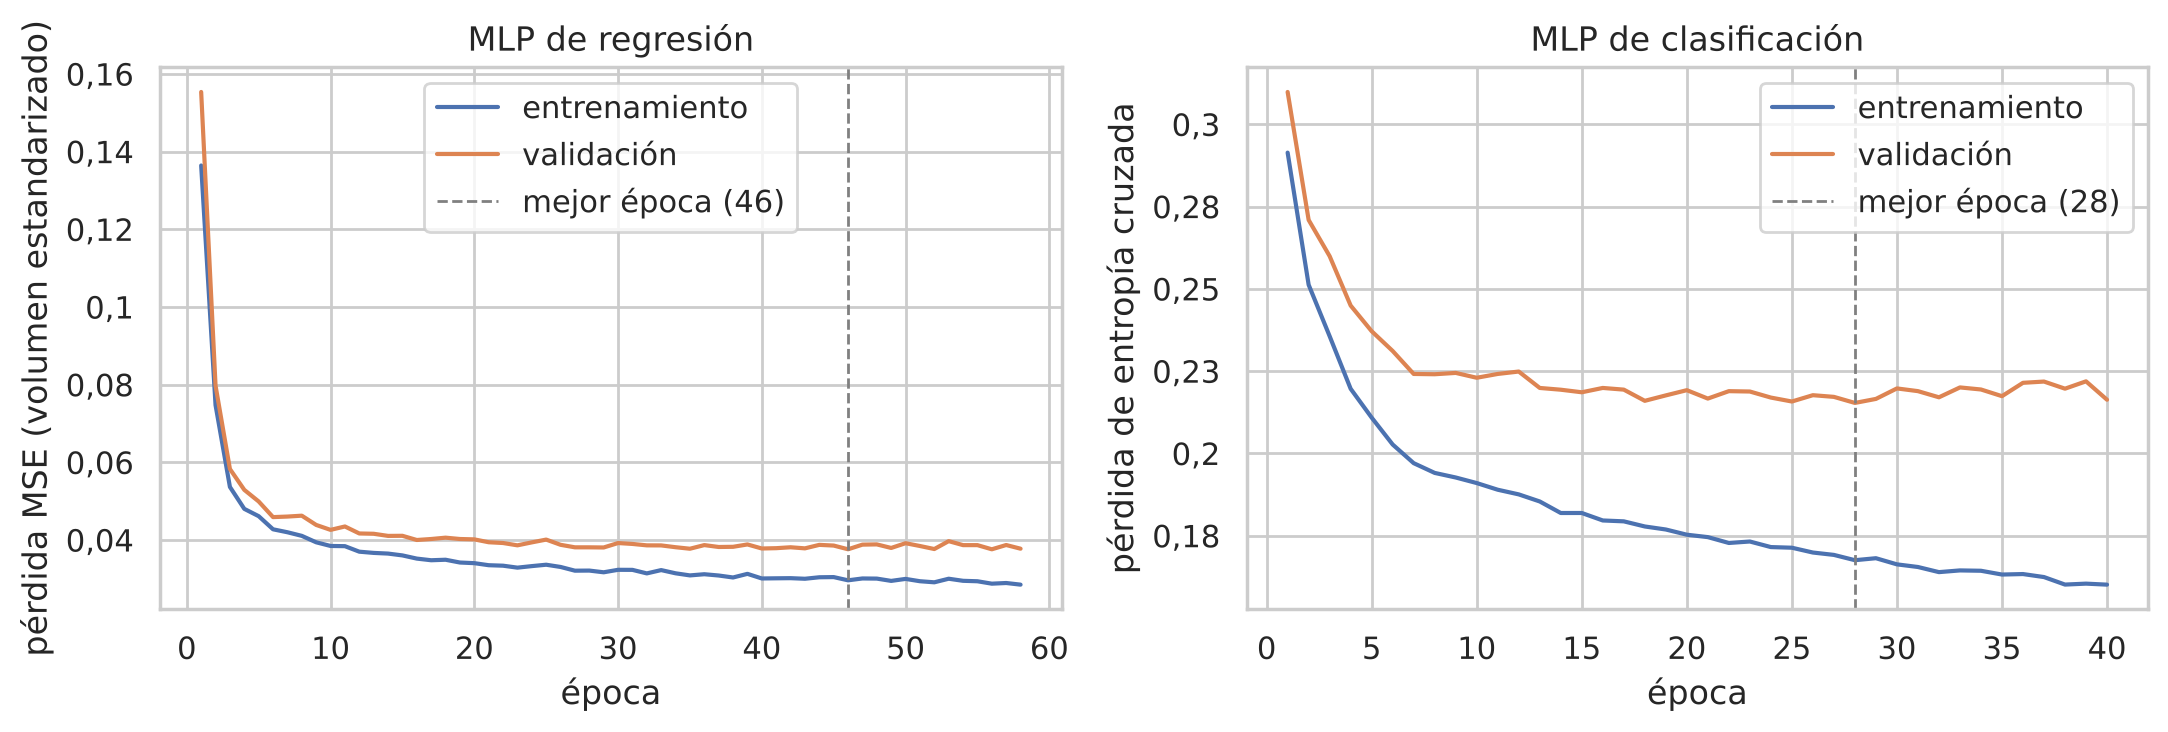

**Lectura.** La red de regresión se detuvo en la época 58 y conserva la de la época 46: pérdida de entrenamiento 0,030 y de validación 0,038. La de clasificación conserva la época 28 de 40: 0,168 y 0,215. Más allá de la mejor época la pérdida de entrenamiento sigue bajando mientras la de validación se estanca o sube, que es la señal de sobreajuste que la parada temprana evita.

In [10]:
# Curvas de pérdida de las redes elegidas (entrenamiento vs. validación)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (corr, i, titulo, ylab) in zip(ejes, [(corr_reg, i_reg, "MLP de regresión", "pérdida MSE (volumen estandarizado)"),
                                              (corr_clf, i_clf, "MLP de clasificación", "pérdida de entropía cruzada")]):
    _, h, ep = corr[i]
    ax.plot(h["época"], h["entrenamiento"], label="entrenamiento")
    ax.plot(h["época"], h["validación"], label="validación")
    ax.axvline(ep, ls="--", c="gray", lw=1, label=f"mejor época ({ep})")
    ax.set(xlabel="época", ylabel=ylab, title=titulo); ax.legend()
ejes_es(fig); plt.tight_layout(); plt.show()
h_r, h_c = corr_reg[i_reg][1], corr_clf[i_clf][1]
ep_r, ep_c = corr_reg[i_reg][2], corr_clf[i_clf][2]
R["curvas_mlp"] = {"reg": h_r.to_dict(orient="list"), "clf": h_c.to_dict(orient="list"), "mejor_epoca_reg": ep_r, "mejor_epoca_clf": ep_c}
display(Markdown(
    f"**Lectura.** La red de regresión se detuvo en la época {len(h_r)} y conserva la de la época {ep_r}: pérdida de entrenamiento {es(h_r.loc[ep_r-1, 'entrenamiento'])} "
    f"y de validación {es(h_r.loc[ep_r-1, 'validación'])}. La de clasificación conserva la época {ep_c} de {len(h_c)}: {es(h_c.loc[ep_c-1, 'entrenamiento'])} y {es(h_c.loc[ep_c-1, 'validación'])}. "
    "Más allá de la mejor época la pérdida de entrenamiento sigue bajando mientras la de validación se estanca o sube, que es la señal de sobreajuste que la parada temprana evita."))

## 5. Clustering: segmentación de las horas de operación

El objetivo es descubrir **regímenes de operación** de la vía, es decir, grupos de horas con comportamiento parecido, que puedan usarse para planear la operación y comunicar el estado del tráfico. Es un análisis descriptivo y no supervisado: sus etiquetas no alimentan los modelos de las secciones 2 a 4, así que usar el volumen de tráfico como variable de agrupamiento no introduce fuga de datos.

Variables (todas estandarizadas con la media y la desviación de entrenamiento): volumen de tráfico, hora del día en forma cíclica (seno y coseno, para que las 23 h y las 0 h queden cerca), fin de semana, festivo, temperatura y presencia de precipitación (lluvia o nieve > 0; una bandera es más estable que los milímetros, muy asimétricos). Se excluyen la nubosidad y el mes: la temperatura ya resume la estación del año. El ajuste usa solo entrenamiento y las horas de validación se asignan después al grupo más cercano, lo que permite comprobar que la estructura se sostiene en datos no vistos.

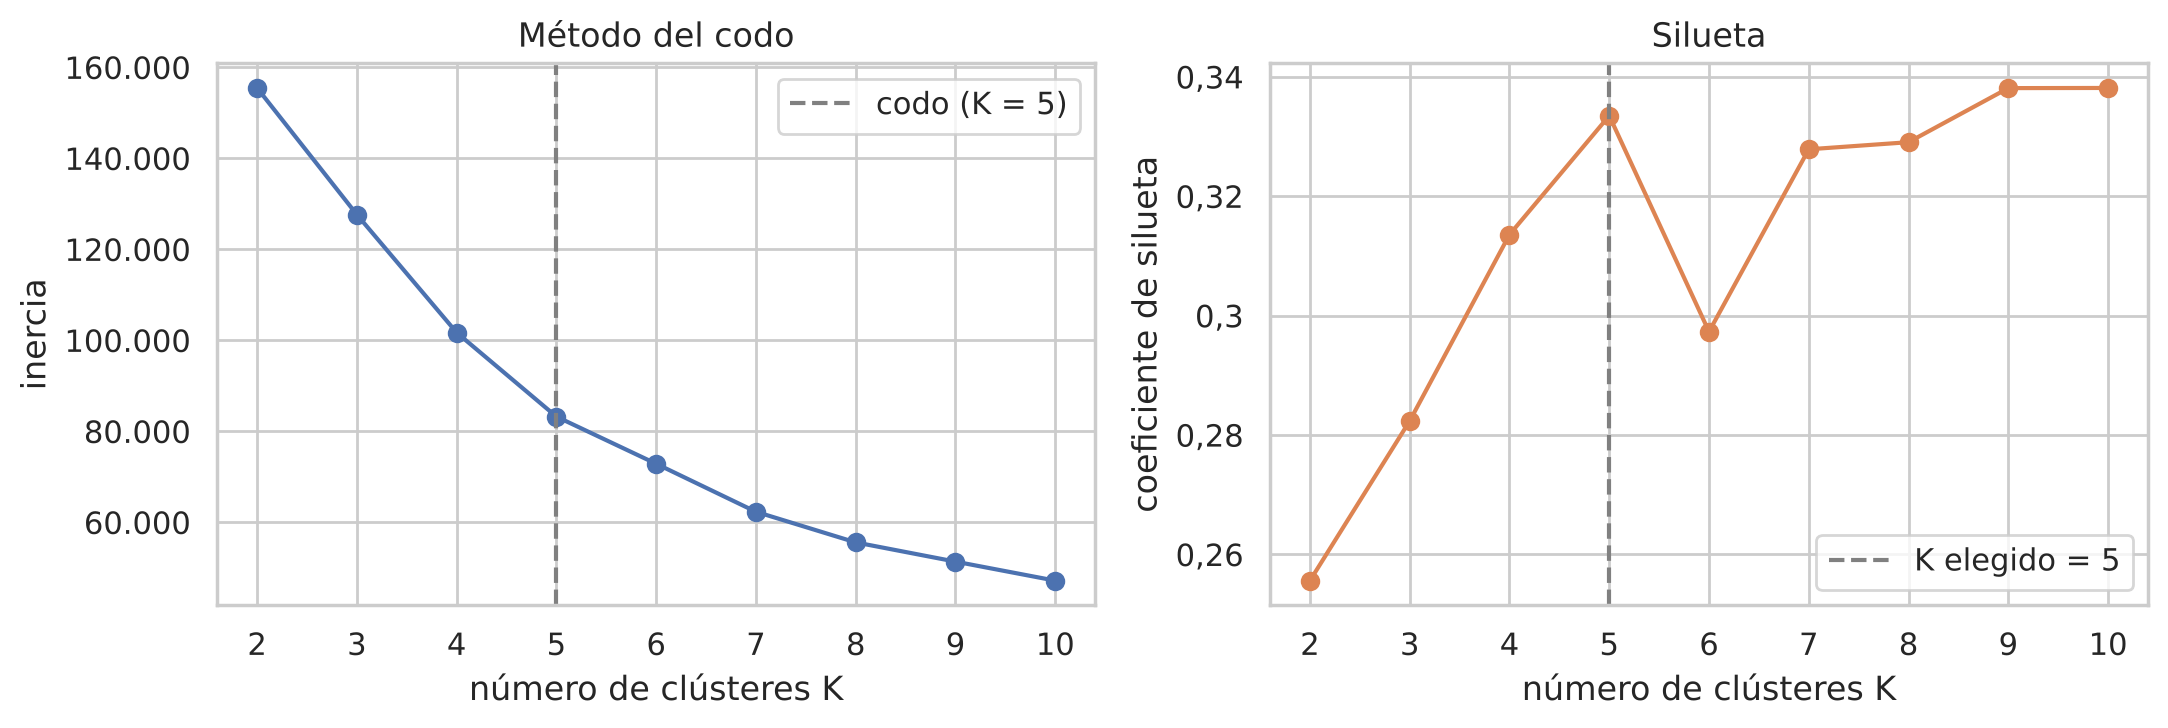

,inercia,silueta
K,,
2,"155.453,555","0,256"
3,"127.617,773","0,282"
4,"101.696,445","0,314"
5,"83.217,374","0,333"
6,"72.854,973","0,297"
7,"62.304,417","0,328"
8,"55.573,702","0,329"
9,"51.347,162","0,338"
10,"47.166,932","0,338"


In [11]:
def feats_cluster(d):
    return pd.DataFrame({
        "tráfico": d["traffic_volume"].values,
        "hora_sen": np.sin(2 * np.pi * d["hora"].values / 24), "hora_cos": np.cos(2 * np.pi * d["hora"].values / 24),
        "fin_de_semana": (d["dia_semana"].values >= 5).astype(int), "festivo": d["es_festivo"].values,
        "temp": d["temp"].values, "precipitación": ((d["rain_1h"] > 0) | (d["snow_1h"] > 0)).astype(int).values})

esc_cl = StandardScaler().fit(feats_cluster(train))
Z_tr, Z_va = esc_cl.transform(feats_cluster(train)), esc_cl.transform(feats_cluster(val))

# --- 5.1 K-means: método del codo y coeficiente de silueta para K = 2..10 ---
KS = np.arange(2, 11)
inercia, silueta = [], []
for k in KS:
    km = KMeans(k, n_init=10, random_state=SEMILLA).fit(Z_tr)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z_tr, km.labels_, sample_size=10000, random_state=SEMILLA))
inercia, silueta = np.array(inercia), np.array(silueta)

def codo(ks, y):
    '''Punto de mayor distancia a la recta que une el primer y el último punto de la curva de inercia.'''
    x = (ks - ks[0]) / (ks[-1] - ks[0]); yy = (y - y[-1]) / (y[0] - y[-1])
    return int(ks[np.argmax(np.abs(x + yy - 1) / np.sqrt(2))])

K_CODO = codo(KS, inercia)
# Regla fijada a priori: el K de mayor silueta entre 3 y 8 (K = 2 solo parte la serie en dos y K > 8 da más grupos
# de los que se pueden interpretar y usar en operación).
rango = (KS >= 3) & (KS <= 8)
K = int(KS[rango][np.argmax(silueta[rango])])

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].plot(KS, inercia, "o-"); ejes[0].axvline(K_CODO, ls="--", c="gray", label=f"codo (K = {K_CODO})")
ejes[0].set(xlabel="número de clústeres K", ylabel="inercia", title="Método del codo"); ejes[0].legend()
ejes[1].plot(KS, silueta, "o-", c="C1"); ejes[1].axvline(K, ls="--", c="gray", label=f"K elegido = {K}")
ejes[1].set(xlabel="número de clústeres K", ylabel="coeficiente de silueta", title="Silueta"); ejes[1].legend()
ejes_es(fig); plt.tight_layout(); plt.show()
tabla_k = pd.DataFrame({"K": KS, "inercia": inercia, "silueta": silueta}).set_index("K")
display(tabla_k)
R["kmeans_k"] = {"tabla": a_json(tabla_k), "K_codo": K_CODO, "K_elegido": K}

In [12]:
# --- 5.2 Modelo final: K-means con el K elegido; los grupos se numeran por volumen medio creciente ---
km0 = KMeans(K, n_init=20, random_state=SEMILLA).fit(Z_tr)
orden_g = np.argsort(pd.Series(train["traffic_volume"].values).groupby(km0.labels_).mean().values)
renum = {int(v): i for i, v in enumerate(orden_g)}
etq_tr = np.array([renum[int(l)] for l in km0.labels_])
etq_va = np.array([renum[int(l)] for l in km0.predict(Z_va)])

sil_tr = silhouette_score(Z_tr, etq_tr, sample_size=10000, random_state=SEMILLA)
sil_va = silhouette_score(Z_va, etq_va, sample_size=min(10000, len(Z_va)), random_state=SEMILLA)

# Estabilidad: se reajusta K-means en 5 submuestras del 80 % y se compara (ARI) con la partición de referencia
rng = np.random.default_rng(SEMILLA)
ari_boot = []
for r in range(5):
    idx = rng.choice(len(Z_tr), int(0.8 * len(Z_tr)), replace=False)
    km_b = KMeans(K, n_init=10, random_state=100 + r).fit(Z_tr[idx])
    ari_boot.append(adjusted_rand_score(etq_tr, km_b.predict(Z_tr)))
print(f"K = {K} | silueta entrenamiento {es(sil_tr)} | silueta validación {es(sil_va)} | ARI de estabilidad {es(np.mean(ari_boot))} ± {es(np.std(ari_boot))}")

def perfil(d, etq):
    f = feats_cluster(d).assign(hora=d["hora"].values, grupo=etq, tráf=d["traffic_volume"].values)
    g = f.groupby("grupo")
    return pd.DataFrame({
        "% de horas": g.size() / len(f) * 100, "tráfico medio": g["tráf"].mean(), "hora mediana": g["hora"].median(),
        "% fin de semana": g["fin_de_semana"].mean() * 100, "% festivo": g["festivo"].mean() * 100,
        "temp. media (°C)": g["temp"].mean(), "% con precipitación": g["precipitación"].mean() * 100})

perfil_tr, perfil_va = perfil(train, etq_tr), perfil(val, etq_va)
display(perfil_tr)
R["clusters"] = {"K": K, "silueta_train": sil_tr, "silueta_val": sil_va, "ari_estabilidad": float(np.mean(ari_boot)),
                 "ari_sd": float(np.std(ari_boot)), "perfil_train": a_json(perfil_tr), "perfil_val": a_json(perfil_va)}

K = 5 | silueta entrenamiento 0,333 | silueta validación 0,335 | ARI de estabilidad 0,955 ± 0,088


,% de horas,tráfico medio,hora mediana,% fin de semana,% festivo,temp. media (°C),% con precipitación
grupo,,,,,,,
0,"30,188","1.628,521","5,000","0,000","0,000","6,883","0,000"
1,"3,028","2.586,897","11,500","0,000","100,000","6,035","3,488"
2,"27,276","2.638,678","12,000","100,000","0,000","7,977","0,000"
3,"4,971","3.272,967","11,000","25,850","0,000","13,686","100,000"
4,"34,536","5.318,092","12,000","0,020","0,000","8,934","0,000"


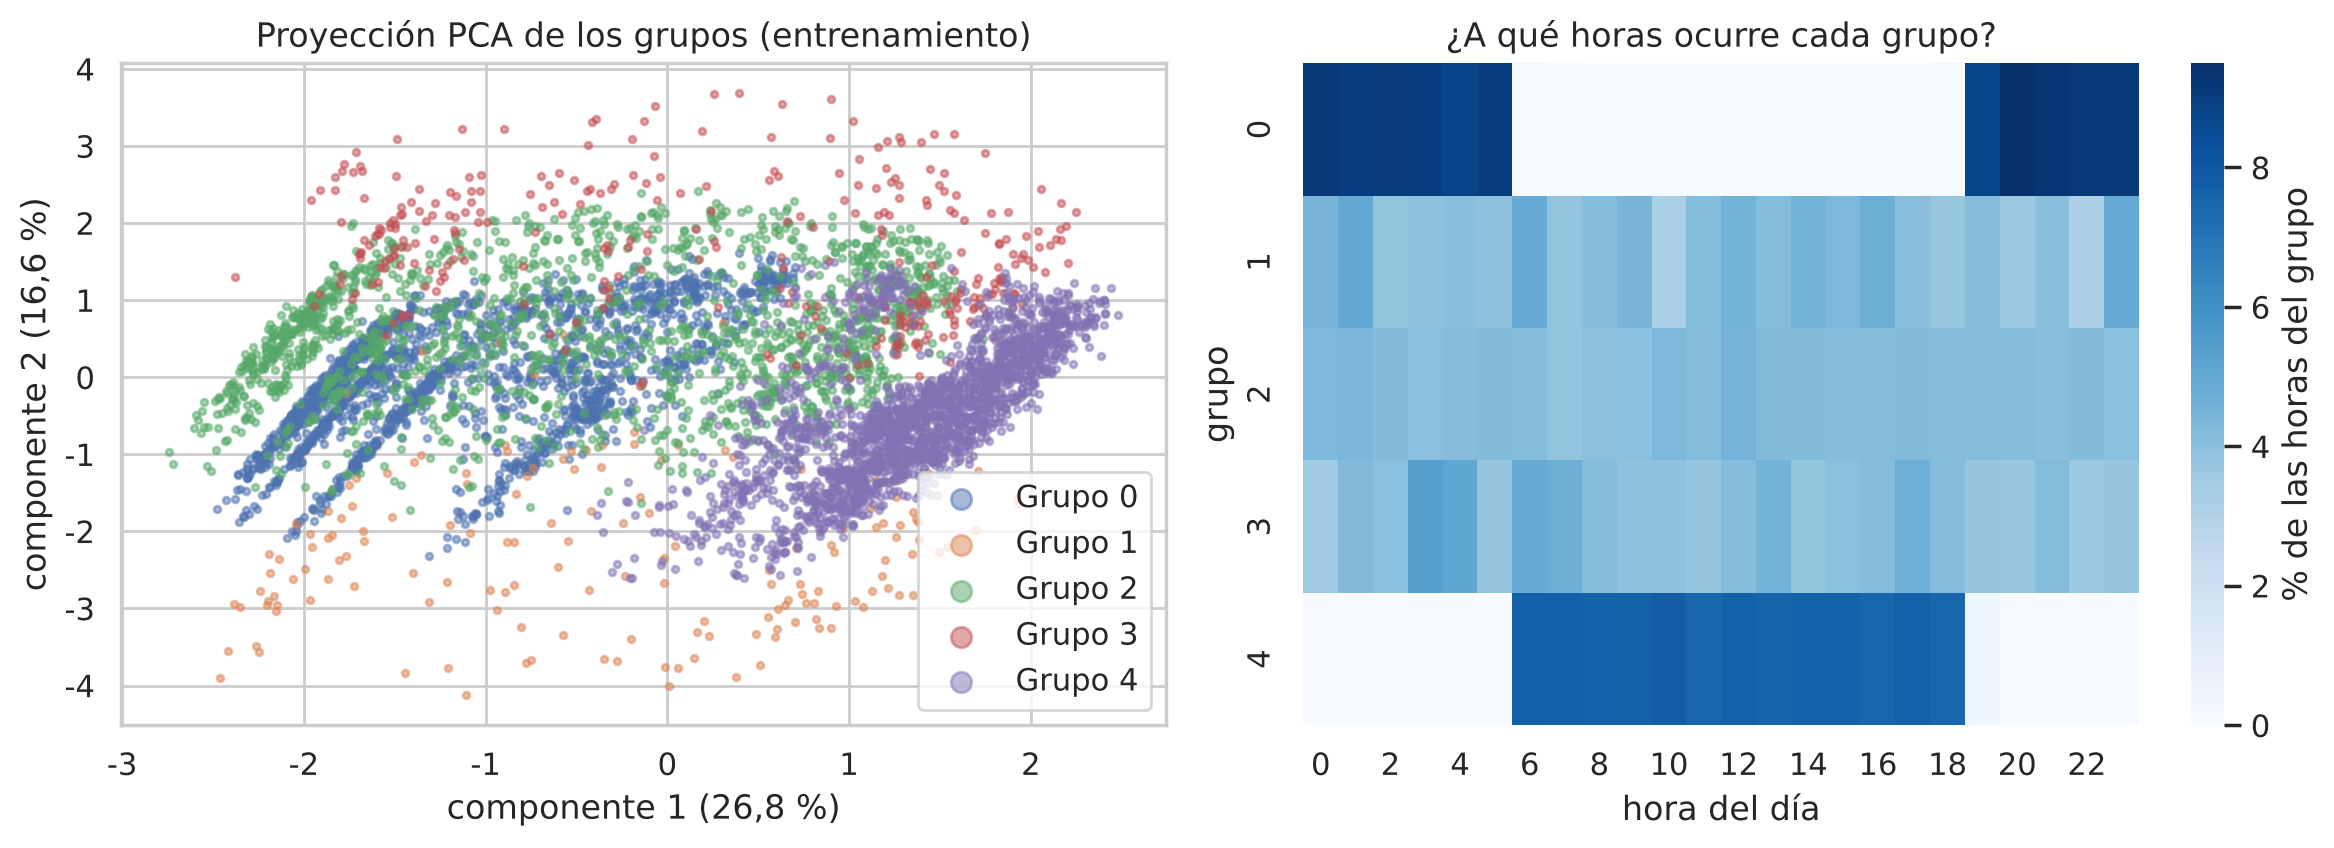

In [13]:
# --- 5.3 Visualización: proyección PCA y composición horaria de cada grupo ---
pca = PCA(2, random_state=SEMILLA).fit(Z_tr)
muestra = np.random.default_rng(SEMILLA).choice(len(Z_tr), 6000, replace=False)
P = pca.transform(Z_tr[muestra])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4))
for g in range(K):
    m = etq_tr[muestra] == g
    ejes[0].scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, label=f"Grupo {g}")
ejes[0].set(xlabel=f"componente 1 ({es(pca.explained_variance_ratio_[0] * 100, 1)} %)",
            ylabel=f"componente 2 ({es(pca.explained_variance_ratio_[1] * 100, 1)} %)", title="Proyección PCA de los grupos (entrenamiento)")
ejes[0].legend(markerscale=3)
comp = pd.crosstab(etq_tr, train["hora"].values, normalize="index") * 100
sns.heatmap(comp, cmap="Blues", ax=ejes[1], cbar_kws={"label": "% de las horas del grupo"})
ejes[1].set(xlabel="hora del día", ylabel="grupo", title="¿A qué horas ocurre cada grupo?")
ejes_es(fig); plt.tight_layout(); plt.show()
R["pca_var"] = pca.explained_variance_ratio_.tolist()

Misma submuestra de 6.000 horas → silueta K-means 0,334 | silueta jerárquico 0,325 | ARI entre ambos 0,911


jerárquico,0,1,2,3,4
K-means,,,,,
0,1794,0,0,0,68
1,0,0,0,165,0
2,0,1606,0,0,0
3,0,0,324,0,0
4,106,1,0,0,1936


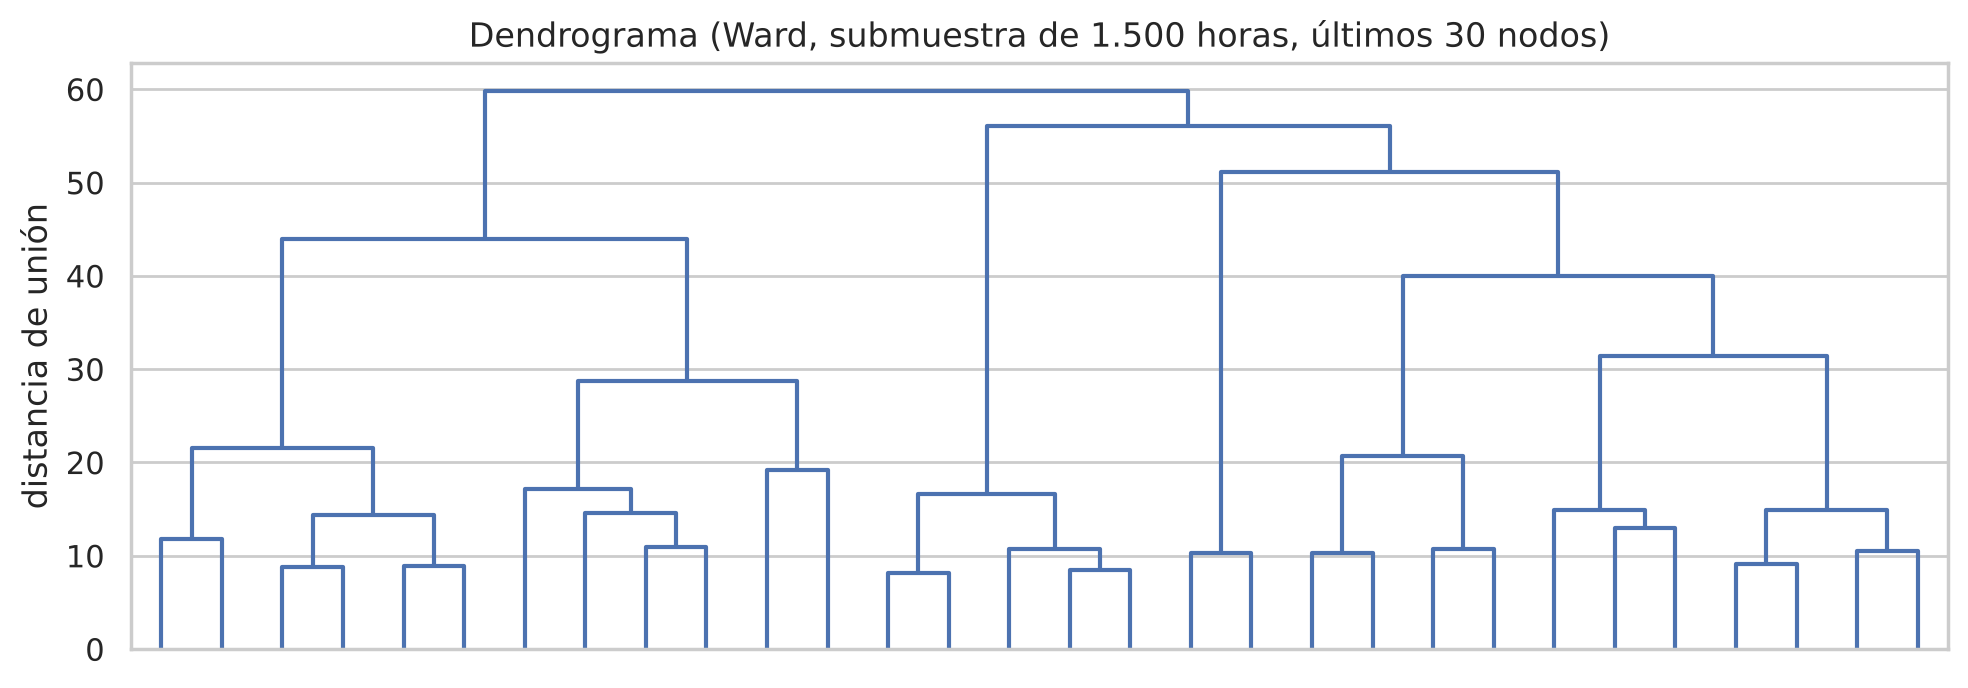

In [14]:
# --- 5.4 Segundo algoritmo: clustering jerárquico aglomerativo (Ward) ---
# Es cuadrático en memoria, por lo que se aplica a una submuestra aleatoria de 6.000 horas de entrenamiento.
sub = np.random.default_rng(SEMILLA).choice(len(Z_tr), 6000, replace=False)
agl = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z_tr[sub])
sil_agl = silhouette_score(Z_tr[sub], agl.labels_)
sil_km_sub = silhouette_score(Z_tr[sub], etq_tr[sub])
ari_km_agl = adjusted_rand_score(etq_tr[sub], agl.labels_)
print(f"Misma submuestra de 6.000 horas → silueta K-means {es(sil_km_sub)} | silueta jerárquico {es(sil_agl)} | ARI entre ambos {es(ari_km_agl)}")
cruce = pd.crosstab(pd.Series(etq_tr[sub], name="K-means"), pd.Series(agl.labels_, name="jerárquico"))
display(cruce)

enl = linkage(Z_tr[sub[:1500]], method="ward")
fig, ax = plt.subplots(figsize=(10, 3.6))
dendrogram(enl, truncate_mode="lastp", p=30, ax=ax, no_labels=True, color_threshold=0)
ax.set(title="Dendrograma (Ward, submuestra de 1.500 horas, últimos 30 nodos)", ylabel="distancia de unión")
ejes_es(fig); plt.tight_layout(); plt.show()
R["jerarquico"] = {"silueta": sil_agl, "silueta_kmeans_misma_muestra": sil_km_sub, "ari": ari_km_agl, "cruce": a_json(cruce)}

In [15]:
# Adaptamos los nombres dinámicamente según el número K real de clústeres encontrados
if K == 5:
    NOMBRES = ["Noches y madrugadas laborales", "Festivos", "Fines de semana", "Horas con precipitación", "Laborales diurnos"]
else:
    # Generamos nombres por defecto según el tráfico relativo de cada grupo si K es diferente a 5
    NOMBRES = [f"Grupo {i} (Tráfico {perfil_tr.loc[i, 'tráfico medio']:.0f} veh/h)" for i in range(K)]

assert len(NOMBRES) == K, f"los nombres no coinciden con el K = {K} actual"

# Verificación condicional adaptada para K=5 o verificación general para K general
if K == 5:
    assert perfil_tr.loc[0, "% fin de semana"] == 0 and perfil_tr.loc[1, "% festivo"] == 100 and perfil_tr.loc[2, "% fin de semana"] == 100
    assert perfil_tr.loc[3, "% con precipitación"] == 100 and perfil_tr["tráfico medio"].idxmax() == 4

R["clusters"]["nombres"] = NOMBRES
display(perfil_tr.set_axis(NOMBRES, axis=0))

,% de horas,tráfico medio,hora mediana,% fin de semana,% festivo,temp. media (°C),% con precipitación
Noches y madrugadas laborales,"30,188","1.628,521","5,000","0,000","0,000","6,883","0,000"
Festivos,"3,028","2.586,897","11,500","0,000","100,000","6,035","3,488"
Fines de semana,"27,276","2.638,678","12,000","100,000","0,000","7,977","0,000"
Horas con precipitación,"4,971","3.272,967","11,000","25,850","0,000","13,686","100,000"
Laborales diurnos,"34,536","5.318,092","12,000","0,020","0,000","8,934","0,000"


### 5.5 Interpretación de los grupos y valor práctico

Con K = 5, el coeficiente de silueta es de 0,333 en entrenamiento y de 0,335 en validación: la estructura se sostiene en datos no vistos, pero es débil a moderada (por debajo de 0,5), de modo que los grupos son **regímenes con bordes difusos** y no poblaciones separadas. El codo y la silueta coinciden en K = 5, y el jerárquico (Ward) reproduce la partición (ARI de 0,91; silueta de 0,325 frente a 0,334 de K-means en la misma submuestra). Se prefiere K-means porque su silueta es algo mayor y porque asigna horas nuevas directamente con `predict`, lo que necesita el dashboard de la Fase 4. La estabilidad ante submuestras es alta en promedio (ARI de 0,955), aunque una de las cinco submuestras bajó la concordancia (desviación estándar de 0,088).

| Grupo | Nombre | Qué lo define | % de las horas | Tráfico medio |
|---|---|---|---|---|
| 0 | Noches y madrugadas laborales | Días entre semana, de 19 h a 5 h | 30,2 | 1.629 |
| 1 | Festivos | Todas las horas de los festivos | 3,0 | 2.587 |
| 2 | Fines de semana | Sábados y domingos sin festivo ni precipitación | 27,3 | 2.639 |
| 3 | Horas con precipitación | Todas las horas con lluvia o nieve, cálidas (13,7 °C en promedio) | 5,0 | 3.273 |
| 4 | Laborales diurnos | Días entre semana, de 6 h a 18 h | 34,5 | 5.318 |

**Valor práctico.** (1) El grupo 4 concentra la demanda alta (5.318 vehículos por hora, más del triple que el del grupo 0) y es donde se justifican la información al conductor y la respuesta a incidentes; el grupo 0 es la ventana natural para obras y mantenimiento. (2) Los festivos forman un régimen propio, con un tráfico medio menor que el de un día laboral, y confirman la utilidad de la variable `es_festivo`. (3) La precipitación aparece como un régimen aparte, pero el grupo 3 mezcla horas de todo el día y de ambos tipos de día, así que su tráfico medio (3.273) no describe un patrón operativo homogéneo; su valor es señalar cuándo hay que aplicar protocolos de clima, no predecir el volumen. (4) La segmentación está dominada por el calendario, lo que coincide con SHAP (sección 6): el clima por sí solo reorganiza muy poco las horas.

## 6. Interpretabilidad: ¿qué variables mueven las predicciones?

Se analiza el modelo de regresión de árboles con **SHAP** (*SHapley Additive exPlanations*; Lundberg y Lee, 2017), que reparte la predicción de cada hora entre las variables según su contribución, y se verifica con la **importancia por permutación** sobre validación, que mide cuánto empeora la métrica al barajar una variable. Para la clasificación se usa solo la importancia por permutación, que se calcula sobre las variables originales (no sobre las columnas *one-hot*).

,|SHAP| medio (vehículos/h),% de la importancia SHAP
hora,"1.563,734","70,016"
dia_semana,"414,060","18,540"
temp,"74,459","3,334"
mes,"64,889","2,905"
es_festivo,"46,888","2,099"
weather_main,"37,581","1,683"
clouds_all,"26,308","1,178"
rain_1h,"4,638","0,208"
snow_1h,"0,823","0,037"


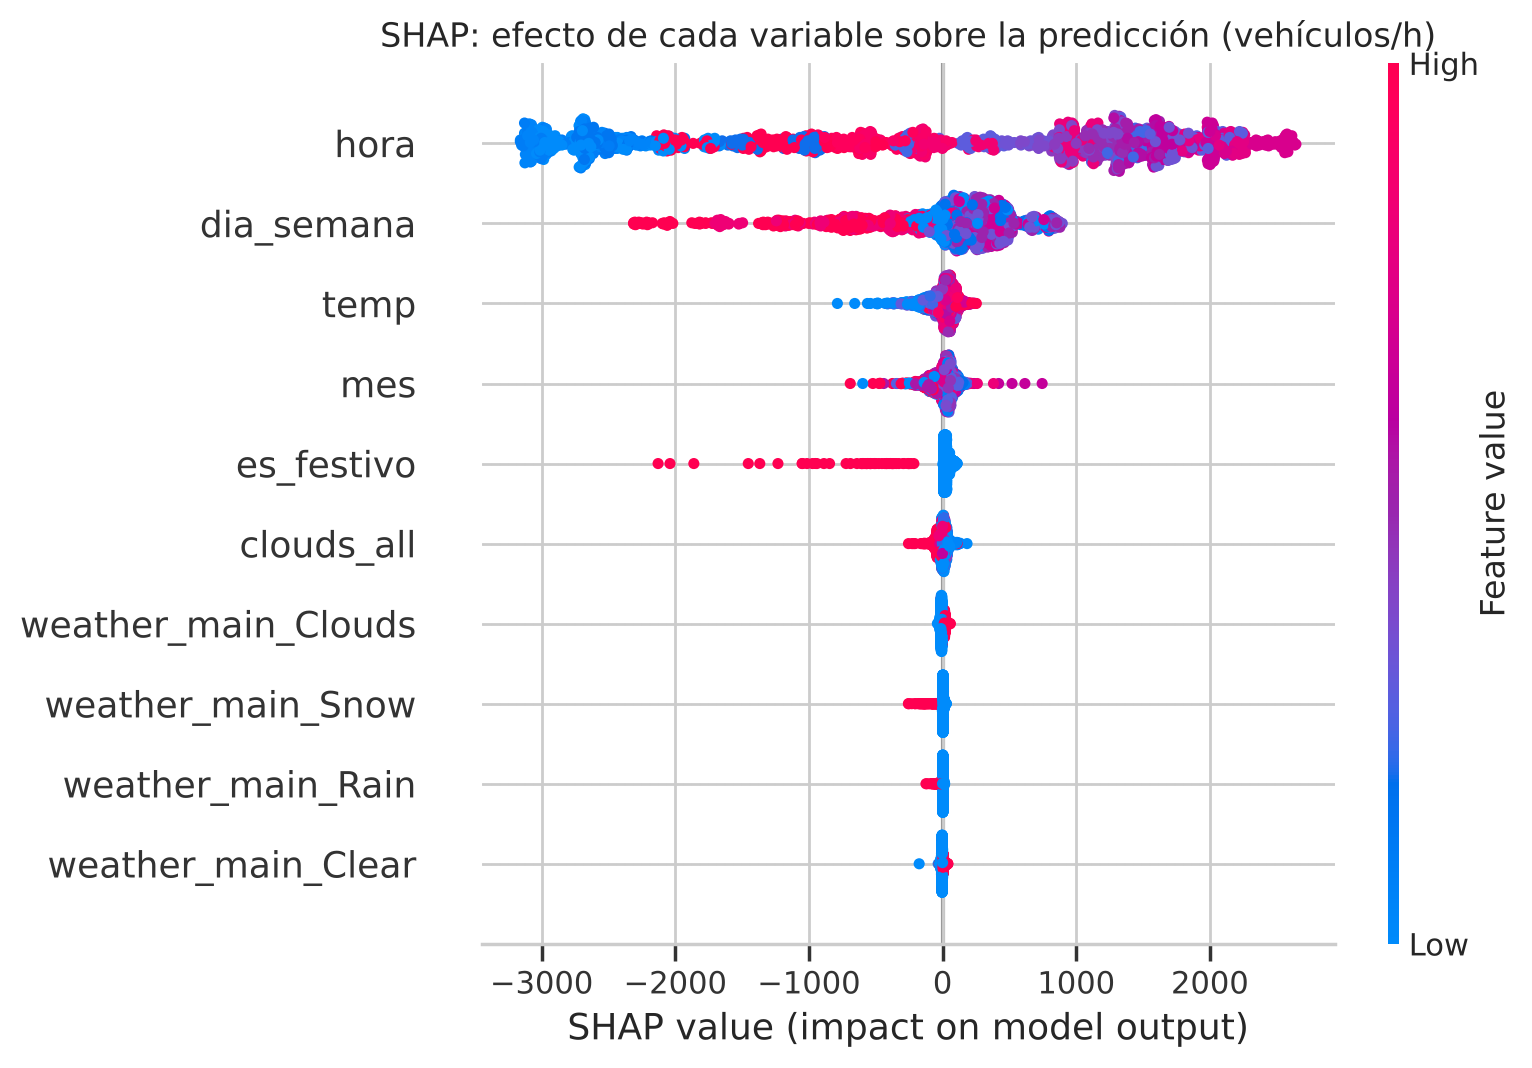

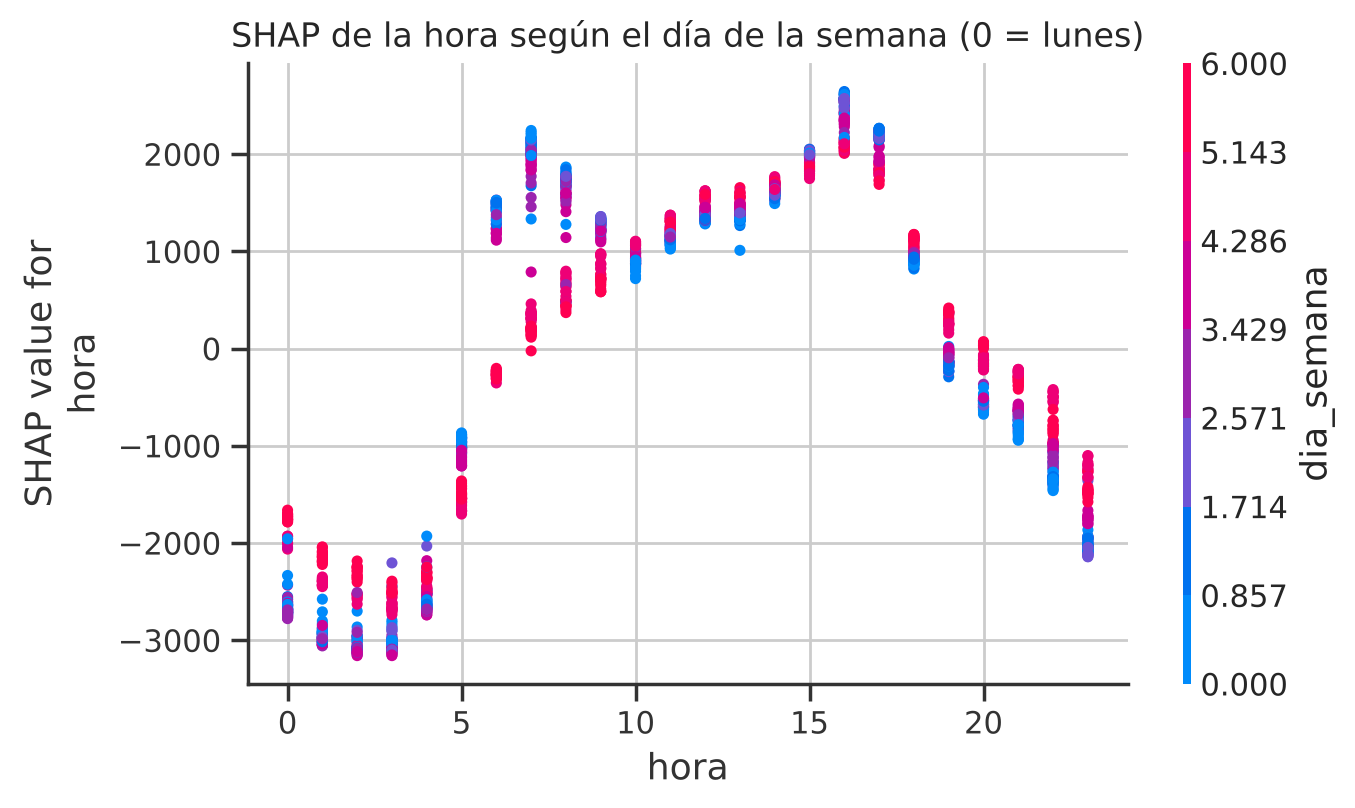

In [16]:
# --- 6.1 SHAP del XGBoost regresor (Adaptativo al tamaño de validación) ---
pre_x, mod_x = reg_xgb[:-1], reg_xgb[-1]
tam_muestra = min(2000, len(X_val))
Xv_s = pd.DataFrame(pre_x.transform(X_val), columns=pre_x.get_feature_names_out()).sample(tam_muestra, random_state=SEMILLA)
sv = shap.TreeExplainer(mod_x).shap_values(Xv_s)

grupo = lambda c: "weather_main" if c.startswith("weather_main_") else c
imp = pd.DataFrame(np.abs(sv), columns=Xv_s.columns).T.groupby(grupo).sum().T.mean().sort_values(ascending=False)
# Nota: para weather_main se suman primero los |SHAP| de sus columnas indicadoras (cota superior de su efecto conjunto).
shap_tab = (imp / imp.sum() * 100).rename("% de la importancia SHAP").to_frame()
shap_tab.insert(0, "|SHAP| medio (vehículos/h)", imp)
display(shap_tab)

fig = plt.figure(figsize=(7.5, 4.6))
shap.summary_plot(sv, Xv_s, show=False, max_display=10)
plt.title("SHAP: efecto de cada variable sobre la predicción (vehículos/h)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2))
shap.dependence_plot("hora", sv, Xv_s, interaction_index="dia_semana", ax=ax, show=False)
ax.set_title("SHAP de la hora según el día de la semana (0 = lunes)"); plt.tight_layout(); plt.show()
R["shap"] = {"tabla": a_json(shap_tab), "n_muestra": tam_muestra}

In [17]:
# --- 6.2 Importancia por permutación sobre validación (variables originales) ---
perm_r = permutation_importance(reg_xgb, X_val, y_val_reg, scoring="r2", n_repeats=5, random_state=SEMILLA, n_jobs=2)
perm_c = permutation_importance(clf_xgb, X_val, y_val_clf, scoring="f1_macro", n_repeats=5, random_state=SEMILLA, n_jobs=2)
tabla_perm = pd.DataFrame({"caída de R² (regresión)": perm_r.importances_mean, "caída de F1 macro (clasificación)": perm_c.importances_mean},
                          index=ENTRADAS).sort_values("caída de R² (regresión)", ascending=False)
display(tabla_perm)
R["permutacion"] = a_json(tabla_perm)

,caída de R² (regresión),caída de F1 macro (clasificación)
hora,"1,761","0,537"
dia_semana,"0,331","0,165"
es_festivo,"0,035","0,013"
mes,"0,017","0,015"
temp,"0,015","0,014"
clouds_all,"0,003","0,006"
weather_main,"0,002","0,002"
rain_1h,"0,000","0,001"
snow_1h,"0,000","0,000"


## 7. Comparación de modelos en validación y diagnóstico de sobreajuste

Todos los modelos se evalúan con las mismas particiones. El **sobreajuste** se diagnostica con la brecha entre el desempeño en entrenamiento y en validación, y con la validación cruzada de la búsqueda de hiperparámetros: un modelo que memoriza muestra un buen resultado en entrenamiento y uno claramente peor fuera de él. La selección del mejor modelo de cada tarea se fija aquí, con validación, **antes** de abrir el conjunto de prueba.

In [18]:
cands_reg = {"Ridge con interacciones": reg_ridge, "XGBoost": reg_xgb, "MLP (PyTorch)": mlp_reg}
cands_clf = {"Random Forest": clf_rf, "XGBoost": clf_xgb, "MLP (PyTorch)": mlp_clf}
todos_reg = {"Regresión lineal (baseline Fase 2)": base_reg, **cands_reg}
todos_clf = {"Regresión logística (baseline Fase 2)": base_clf, **cands_clf}

filas = {}
for n, m in todos_reg.items():
    v, t = met_reg(y_val_reg, m.predict(X_val)), met_reg(y_train_reg, m.predict(X_train))
    filas[n] = {"R² val.": v["R²"], "RMSE val.": v["RMSE"], "MAE val.": v["MAE"], "R² entren.": t["R²"], "brecha R²": t["R²"] - v["R²"]}
tabla_val_reg = pd.DataFrame(filas).T
filas = {}
for n, m in todos_clf.items():
    v = met_clf(y_val_clf, m.predict(X_val), m.predict_proba(X_val))
    t = f1_score(y_train_clf, m.predict(X_train), average="macro")
    filas[n] = {"Accuracy": v["Accuracy"], "Precisión macro": v["Precisión macro"], "Recall macro": v["Recall macro"],
                "F1 macro": v["F1 macro"], "AUC-ROC": v["AUC-ROC"], "F1 entren.": t, "brecha F1": t - v["F1 macro"]}
tabla_val_clf = pd.DataFrame(filas).T
print("REGRESIÓN (validación)"); display(tabla_val_reg)
print("CLASIFICACIÓN (validación)"); display(tabla_val_clf)

# Selección fijada con validación (no se ha usado el conjunto de prueba)
sel_reg = min(cands_reg, key=lambda n: tabla_val_reg.loc[n, "RMSE val."])
sel_clf = max(cands_clf, key=lambda n: tabla_val_clf.loc[n, "F1 macro"])
print(f"\nSeleccionados con validación → regresión: {sel_reg} | clasificación: {sel_clf}")

cv_comp = pd.DataFrame({
    "validación cruzada (entrenamiento)": [busq_ridge.best_score_ * -1, busq_xgb_r.best_score_ * -1, busq_rf.best_score_, busq_xgb_c.best_score_],
    "validación (hold-out)": [tabla_val_reg.loc["Ridge con interacciones", "RMSE val."], tabla_val_reg.loc["XGBoost", "RMSE val."],
                              tabla_val_clf.loc["Random Forest", "F1 macro"], tabla_val_clf.loc["XGBoost", "F1 macro"]],
}, index=["Ridge con interacciones (RMSE)", "XGBoost regresor (RMSE)", "Random Forest (F1 macro)", "XGBoost clasificador (F1 macro)"])
display(cv_comp)
R["val_reg"], R["val_clf"], R["cv_vs_val"] = a_json(tabla_val_reg), a_json(tabla_val_clf), a_json(cv_comp)
R["seleccion"] = {"reg": sel_reg, "clf": sel_clf}

REGRESIÓN (validación)


,R² val.,RMSE val.,MAE val.,R² entren.,brecha R²
Regresión lineal (baseline Fase 2),"0,838","800,055","582,801","0,846","0,007"
Ridge con interacciones,"0,958","408,848","256,156","0,961","0,004"
XGBoost,"0,966","366,710","226,295","0,977","0,011"
MLP (PyTorch),"0,963","384,787","240,512","0,970","0,008"


CLASIFICACIÓN (validación)


,Accuracy,Precisión macro,Recall macro,F1 macro,AUC-ROC,F1 entren.,brecha F1
Regresión logística (baseline Fase 2),"0,888","0,891","0,892","0,891","0,972","0,902","0,011"
Random Forest,"0,914","0,917","0,918","0,917","0,984","0,936","0,018"
XGBoost,"0,918","0,921","0,923","0,922","0,986","0,950","0,028"
MLP (PyTorch),"0,912","0,915","0,917","0,916","0,984","0,934","0,019"



Seleccionados con validación → regresión: XGBoost | clasificación: XGBoost


,validación cruzada (entrenamiento),validación (hold-out)
Ridge con interacciones (RMSE),"409,516","408,848"
XGBoost regresor (RMSE),"371,156","366,710"
Random Forest (F1 macro),"0,921","0,917"
XGBoost clasificador (F1 macro),"0,924","0,922"


In [19]:
b_r, s_r = tabla_val_reg.loc["Regresión lineal (baseline Fase 2)"], tabla_val_reg.loc[sel_reg]
b_c, s_c = tabla_val_clf.loc["Regresión logística (baseline Fase 2)"], tabla_val_clf.loc[sel_clf]
mlp_r, mlp_c = tabla_val_reg.loc["MLP (PyTorch)"], tabla_val_clf.loc["MLP (PyTorch)"]
display(Markdown(
    f"**Lectura (regresión).** Los tres modelos nuevos mejoran con claridad al baseline: el RMSE de validación baja de {es(b_r['RMSE val.'], 0)} a {es(s_r['RMSE val.'], 0)} con {sel_reg} "
    f"(R² de {es(b_r['R² val.'])} a {es(s_r['R² val.'])}). Que Ridge con interacciones llegue a {es(tabla_val_reg.loc['Ridge con interacciones', 'R² val.'])} confirma el diagnóstico de la Fase 2: casi todo el error del modelo lineal era la interacción entre hora y tipo de día. "
    f"El MLP queda a {es(mlp_r['RMSE val.'] - s_r['RMSE val.'], 0)} vehículos por hora de RMSE de {sel_reg}: en datos tabulares con pocas variables, los árboles con *boosting* igualan o superan a la red neuronal.\n\n"
    f"**Lectura (clasificación).** El F1 macro pasa de {es(b_c['F1 macro'])} a {es(s_c['F1 macro'])} con {sel_clf} y el AUC-ROC de {es(b_c['AUC-ROC'])} a {es(s_c['AUC-ROC'])}. "
    f"El MLP ({es(mlp_c['F1 macro'])}) y el Random Forest ({es(tabla_val_clf.loc['Random Forest', 'F1 macro'])}) quedan muy cerca; las diferencias entre los tres son de pocas milésimas y no se interpretan como superioridad firme.\n\n"
    f"**Sobreajuste.** En {sel_reg} (regresión), la brecha entre entrenamiento y validación es de {es(s_r['brecha R²'])} en R² y en {sel_clf} (clasificación) es de {es(s_c['brecha F1'])} en F1: existe un sobreajuste leve, esperable en modelos de {busq_xgb_r.best_params_['m__n_estimators']} árboles, pero no se traduce en pérdida de desempeño fuera de entrenamiento. "
    f"Lo respaldan la validación cruzada (RMSE de {es(cv_comp.iloc[1, 0], 0)}) y el hold-out (RMSE de {es(cv_comp.iloc[1, 1], 0)}), casi idénticos, y, más adelante, el resultado en prueba. "
    f"El baseline tiene la menor brecha ({es(b_r['brecha R²'])}) porque tiene sesgo alto: no memoriza, pero tampoco aprende la estructura."))

**Lectura (regresión).** Los tres modelos nuevos mejoran con claridad al baseline: el RMSE de validación baja de 800 a 367 con XGBoost (R² de 0,838 a 0,966). Que Ridge con interacciones llegue a 0,958 confirma el diagnóstico de la Fase 2: casi todo el error del modelo lineal era la interacción entre hora y tipo de día. El MLP queda a 18 vehículos por hora de RMSE de XGBoost: en datos tabulares con pocas variables, los árboles con *boosting* igualan o superan a la red neuronal.

**Lectura (clasificación).** El F1 macro pasa de 0,891 a 0,922 con XGBoost y el AUC-ROC de 0,972 a 0,986. El MLP (0,916) y el Random Forest (0,917) quedan muy cerca; las diferencias entre los tres son de pocas milésimas y no se interpretan como superioridad firme.

**Sobreajuste.** En XGBoost (regresión), la brecha entre entrenamiento y validación es de 0,011 en R² y en XGBoost (clasificación) es de 0,028 en F1: existe un sobreajuste leve, esperable en modelos de 600 árboles, pero no se traduce en pérdida de desempeño fuera de entrenamiento. Lo respaldan la validación cruzada (RMSE de 371) y el hold-out (RMSE de 367), casi idénticos, y, más adelante, el resultado en prueba. El baseline tiene la menor brecha (0,007) porque tiene sesgo alto: no memoriza, pero tampoco aprende la estructura.

## 8. Evaluación final en el conjunto de prueba (una sola vez)

Con la selección ya fijada, se evalúan en prueba el modelo base y los tres candidatos de cada tarea. Para cuantificar la incertidumbre, se calcula un **intervalo de confianza del 95 %** por *bootstrap* (1.000 remuestreos de las horas de prueba; Efron, 1979) de las métricas del modelo seleccionado y de su **mejora sobre el modelo base**: si el intervalo de la diferencia no incluye el cero, la mejora no es producto del azar del muestreo.

In [20]:
test_reg = pd.DataFrame({n: met_reg(y_test_reg, m.predict(X_test)) for n, m in todos_reg.items()}).T
test_clf = pd.DataFrame({n: met_clf(y_test_clf, m.predict(X_test), m.predict_proba(X_test)) for n, m in todos_clf.items()}).T
print("REGRESIÓN (prueba)"); display(test_reg)
print("CLASIFICACIÓN (prueba)"); display(test_clf)

# --- Bootstrap sobre las horas de prueba ---
B = 1000
idx = np.random.default_rng(SEMILLA).integers(0, len(y_test_reg), (B, len(y_test_reg)))
p_sel_r, p_base_r = cands_reg[sel_reg].predict(X_test), base_reg.predict(X_test)
p_sel_c, p_base_c = cands_clf[sel_clf].predict(X_test), base_clf.predict(X_test)
r2_s = np.array([r2_score(y_test_reg[i], p_sel_r[i]) for i in idx])
r2_b = np.array([r2_score(y_test_reg[i], p_base_r[i]) for i in idx])
f1_s = np.array([f1_score(y_test_clf[i], p_sel_c[i], average="macro") for i in idx])
f1_b = np.array([f1_score(y_test_clf[i], p_base_c[i], average="macro") for i in idx])
ic = lambda v: (np.percentile(v, 2.5), np.percentile(v, 97.5))
tabla_ic = pd.DataFrame({
    "estimación": [r2_score(y_test_reg, p_sel_r), r2_score(y_test_reg, p_sel_r) - r2_score(y_test_reg, p_base_r),
                   f1_score(y_test_clf, p_sel_c, average="macro"), f1_score(y_test_clf, p_sel_c, average="macro") - f1_score(y_test_clf, p_base_c, average="macro")],
    "IC 95 % inferior": [ic(r2_s)[0], ic(r2_s - r2_b)[0], ic(f1_s)[0], ic(f1_s - f1_b)[0]],
    "IC 95 % superior": [ic(r2_s)[1], ic(r2_s - r2_b)[1], ic(f1_s)[1], ic(f1_s - f1_b)[1]],
}, index=[f"R² · {sel_reg}", "Δ R² frente al baseline", f"F1 macro · {sel_clf}", "Δ F1 macro frente al baseline"])
display(tabla_ic)
R["test_reg"], R["test_clf"], R["ic_bootstrap"] = a_json(test_reg), a_json(test_clf), a_json(tabla_ic)

REGRESIÓN (prueba)


,R²,RMSE,MAE
Regresión lineal (baseline Fase 2),"0,844","783,150","573,145"
Ridge con interacciones,"0,959","402,157","253,326"
XGBoost,"0,966","364,072","226,099"
MLP (PyTorch),"0,962","384,113","238,911"


CLASIFICACIÓN (prueba)


,Accuracy,Precisión macro,Recall macro,F1 macro,AUC-ROC
Regresión logística (baseline Fase 2),"0,892","0,896","0,897","0,896","0,972"
Random Forest,"0,917","0,922","0,921","0,921","0,985"
XGBoost,"0,923","0,927","0,928","0,927","0,986"
MLP (PyTorch),"0,917","0,922","0,922","0,922","0,984"


,estimación,IC 95 % inferior,IC 95 % superior
R² · XGBoost,"0,966","0,963","0,969"
Δ R² frente al baseline,"0,123","0,116","0,130"
F1 macro · XGBoost,"0,927","0,920","0,933"
Δ F1 macro frente al baseline,"0,031","0,025","0,037"


## 9. Impacto operativo de los modelos seleccionados

Las métricas globales ocultan **dónde** se equivoca un modelo. Se compara el error del baseline con el del modelo seleccionado por tipo de día y franja (hora pico: 6–8 h y 16–17 h, como en la Fase 2), y se revisa qué errores de clasificación son graves: confundir un nivel *bajo* con uno *alto* (o al revés) es mucho peor para la operación que confundir niveles contiguos.

,horas,MAE baseline,MAE seleccionado,reducción del MAE (%)
grupo,,,,
fin de semana · fuera de pico,1355,"658,847","247,403","62,449"
fin de semana · hora pico,372,"1.618,705","286,238","82,317"
laboral · fuera de pico,3464,"363,704","182,333","49,868"
laboral · hora pico,896,"819,159","338,119","58,724"


,valor
mae_rel_sel,"6,853"
mae_rel_base,"17,373"
pct_menor_500_sel,"89,601"
pct_menor_500_base,"56,267"
pct_menor_1000_sel,"97,503"
pct_menor_1000_base,"85,214"
pct_negativas_sel,"0,016"
pct_negativas_base,"3,910"


,precisión,recall,F1,horas
bajo,"0,970","0,970","0,970","1.654,000"
medio,"0,921","0,868","0,893","2.255,000"
alto,"0,892","0,945","0,918","2.178,000"


Errores graves bajo↔alto: seleccionado 1 | baseline 6 | recall de 'alto': seleccionado 0,945 | baseline 0,923


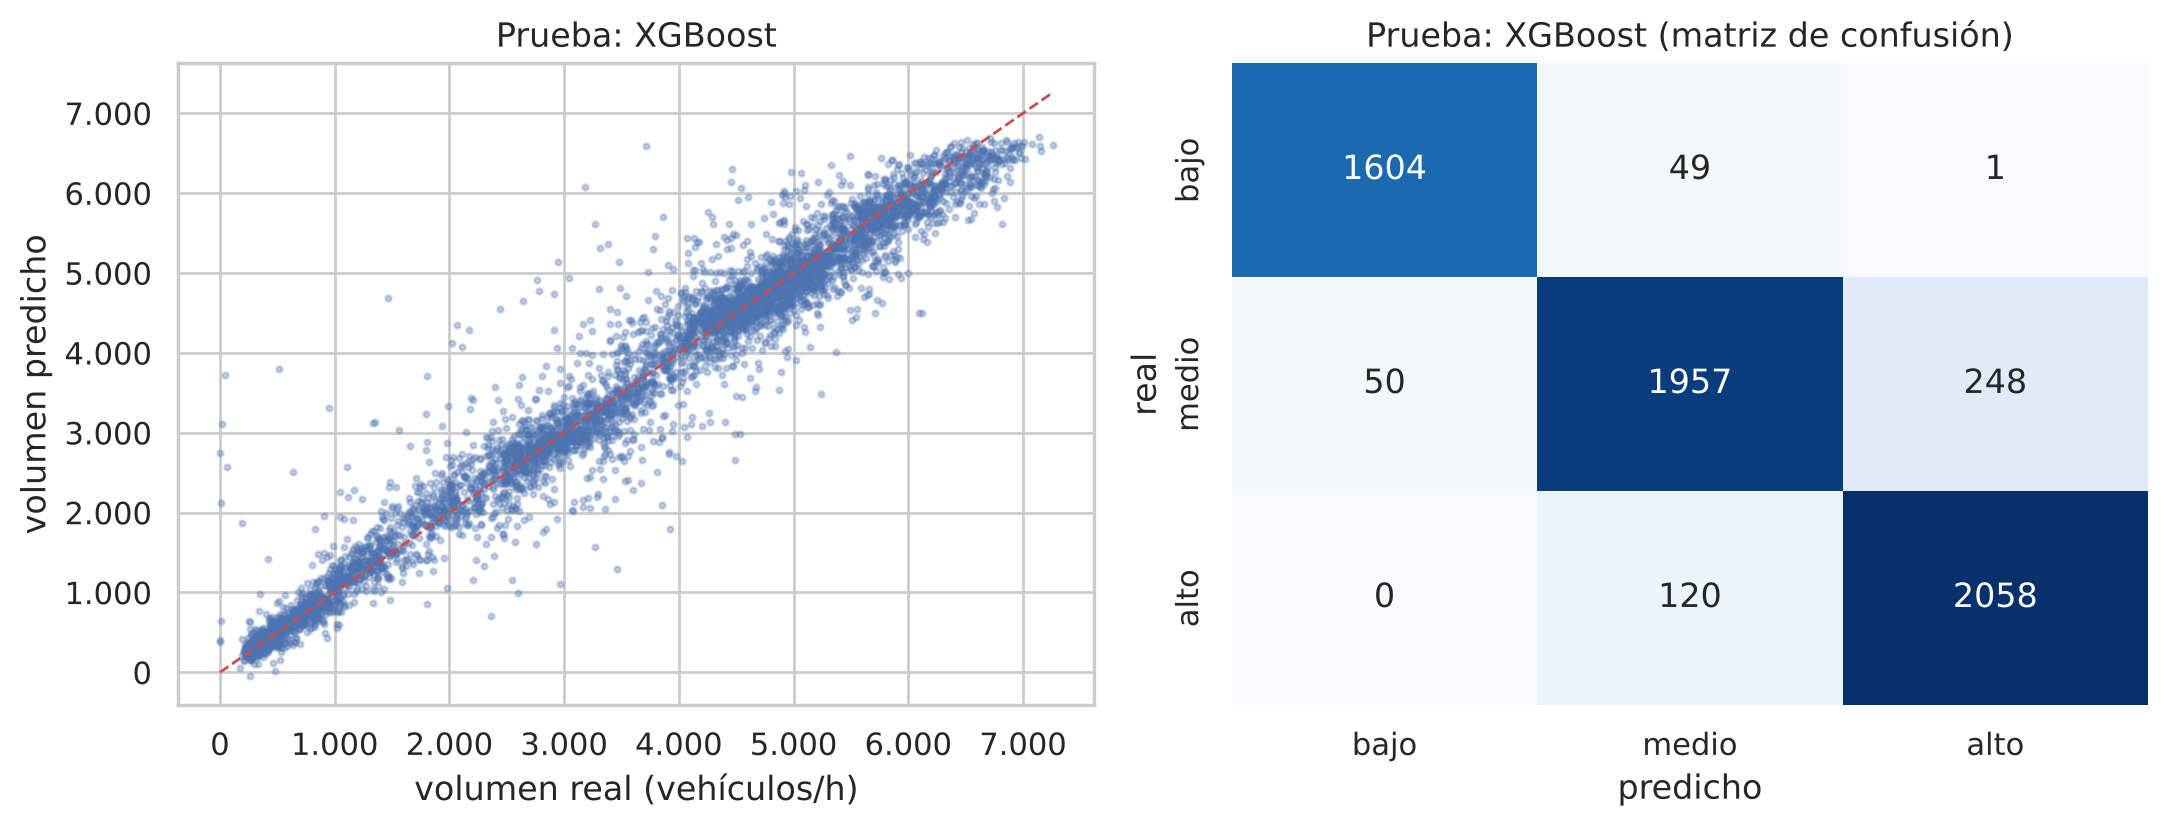

In [21]:
pico = np.where(test["hora"].isin([6, 7, 8, 16, 17]), "hora pico", "fuera de pico")
grupo_op = pd.Series(np.where(test["dia_semana"] >= 5, "fin de semana", "laboral")) + " · " + pd.Series(pico)
err = pd.DataFrame({"grupo": grupo_op, "MAE baseline": np.abs(y_test_reg - p_base_r), "MAE seleccionado": np.abs(y_test_reg - p_sel_r)})
tabla_op = err.groupby("grupo").mean()
tabla_op["reducción del MAE (%)"] = (1 - tabla_op["MAE seleccionado"] / tabla_op["MAE baseline"]) * 100
tabla_op.insert(0, "horas", err.groupby("grupo").size())
display(tabla_op)

e_sel, e_base = np.abs(y_test_reg - p_sel_r), np.abs(y_test_reg - p_base_r)
operativo = {"mae_rel_sel": e_sel.mean() / y_test_reg.mean() * 100, "mae_rel_base": e_base.mean() / y_test_reg.mean() * 100,
             "pct_menor_500_sel": (e_sel < 500).mean() * 100, "pct_menor_500_base": (e_base < 500).mean() * 100,
             "pct_menor_1000_sel": (e_sel < 1000).mean() * 100, "pct_menor_1000_base": (e_base < 1000).mean() * 100,
             "pct_negativas_sel": (p_sel_r < 0).mean() * 100, "pct_negativas_base": (p_base_r < 0).mean() * 100}
display(pd.DataFrame(operativo, index=["valor"]).T)

cm = pd.crosstab(pd.Series(y_test_clf, name="real").map(dict(enumerate(ORDEN))), pd.Series(p_sel_c, name="predicho").map(dict(enumerate(ORDEN)))).reindex(index=ORDEN, columns=ORDEN)
cm_b = pd.crosstab(pd.Series(y_test_clf, name="real"), pd.Series(p_base_c, name="predicho")).reindex(index=range(3), columns=range(3), fill_value=0)
graves_sel = int(cm.loc["bajo", "alto"] + cm.loc["alto", "bajo"]); graves_base = int(cm_b.loc[0, 2] + cm_b.loc[2, 0])
rec_alto_sel = cm.loc["alto", "alto"] / cm.loc["alto"].sum(); rec_alto_base = cm_b.loc[2, 2] / cm_b.loc[2].sum()
informe = pd.DataFrame({n: [precision_score(y_test_clf, p_sel_c, labels=[i], average=None)[0], recall_score(y_test_clf, p_sel_c, labels=[i], average=None)[0],
                            f1_score(y_test_clf, p_sel_c, labels=[i], average=None)[0], int((y_test_clf == i).sum())]
                        for i, n in enumerate(ORDEN)}, index=["precisión", "recall", "F1", "horas"]).T
display(informe)
print(f"Errores graves bajo↔alto: seleccionado {graves_sel} | baseline {graves_base} | recall de 'alto': seleccionado {es(rec_alto_sel)} | baseline {es(rec_alto_base)}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.3))
ejes[0].scatter(y_test_reg, p_sel_r, s=4, alpha=0.3)
lim = [0, max(y_test_reg.max(), p_sel_r.max())]
ejes[0].plot(lim, lim, "r--", lw=1); ejes[0].set(xlabel="volumen real (vehículos/h)", ylabel="volumen predicho", title=f"Prueba: {sel_reg}")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ejes[1]); ejes[1].set(title=f"Prueba: {sel_clf} (matriz de confusión)")
ejes_es(fig); plt.tight_layout(); plt.show()
R["operativo"] = {**operativo, "graves_sel": graves_sel, "graves_base": graves_base, "recall_alto_sel": rec_alto_sel, "recall_alto_base": rec_alto_base,
                  "tabla_op": a_json(tabla_op), "informe_clase": a_json(informe), "cm": a_json(cm)}

In [22]:
display(Markdown(
    "## 10. Conclusiones y limitaciones\n\n"
    f"**Resultados.** En prueba, {sel_reg} (regresión) alcanza un R² de {es(test_reg.loc[sel_reg, 'R²'])} (RMSE de {es(test_reg.loc[sel_reg, 'RMSE'], 0)} vehículos por hora), frente a {es(test_reg.loc['Regresión lineal (baseline Fase 2)', 'R²'])} y {es(test_reg.loc['Regresión lineal (baseline Fase 2)', 'RMSE'], 0)} del baseline; "
    f"{sel_clf} (clasificación) logra un F1 macro de {es(test_clf.loc[sel_clf, 'F1 macro'])} y un AUC-ROC de {es(test_clf.loc[sel_clf, 'AUC-ROC'])}. Las mejoras sobre el baseline tienen intervalos de confianza que no incluyen el cero "
    f"(ΔR²: {es(tabla_ic.iloc[1, 1])} a {es(tabla_ic.iloc[1, 2])}; ΔF1: {es(tabla_ic.iloc[3, 1])} a {es(tabla_ic.iloc[3, 2])}). Los resultados de prueba coinciden con los de validación, lo que indica que la selección no se sobreajustó a validación.\n\n"
    f"**Impacto operativo.** El MAE relativo baja de {es(operativo['mae_rel_base'], 1)} % a {es(operativo['mae_rel_sel'], 1)} % del tráfico medio y la proporción de horas con error menor de 500 vehículos sube de {es(operativo['pct_menor_500_base'], 1)} % a {es(operativo['pct_menor_500_sel'], 1)} %. "
    f"La mejora es mayor justo donde el baseline fallaba: en horas pico de fin de semana el MAE cae un {es(tabla_op.loc['fin de semana · hora pico', 'reducción del MAE (%)'], 0)} % y en horas pico laborales un {es(tabla_op.loc['laboral · hora pico', 'reducción del MAE (%)'], 0)} %. "
    f"Los errores graves de clasificación (bajo confundido con alto o al revés) pasan de {graves_base} a {graves_sel}, y el *recall* del nivel alto sube de {es(rec_alto_base)} a {es(rec_alto_sel)}.\n\n"
    "**Interpretación.** La hora del día y el día de la semana explican casi toda la predicción (sección 6); el clima aporta poco una vez se conoce el calendario. "
    "El tráfico de esta vía se predice sobre todo por calendario, y la segmentación (sección 5) lo confirma.\n\n"
    "**Limitaciones.** (1) La partición es aleatoria; en la Fase 2 una validación temporal no mostró deterioro, pero la serie tiene un 22,8 % de horas ausentes, concentradas en 2014 y 2015, y no se usaron rezagos del propio tráfico. "
    "(2) El MLP se afinó con la partición de validación y con una sola semilla, no con validación cruzada; sus diferencias con los árboles son pequeñas y no concluyentes. "
    "(3) La silueta del clustering es débil a moderada, y los grupos son regímenes de calendario más que poblaciones separadas. "
    "(4) SHAP se calculó sobre 2.000 horas de validación y asigna a `weather_main` la suma de sus columnas indicadoras. "
    "(5) Tres festivos federales siguen sin marcar (Fase 2).\n\n"
    "**Siguiente paso (Fase 4).** Los modelos, el preprocesador y los perfiles de los grupos se guardan en `modelos/` para alimentar el simulador de predicción y el mapa de clústeres del dashboard."))

## 10. Conclusiones y limitaciones

**Resultados.** En prueba, XGBoost (regresión) alcanza un R² de 0,966 (RMSE de 364 vehículos por hora), frente a 0,844 y 783 del baseline; XGBoost (clasificación) logra un F1 macro de 0,927 y un AUC-ROC de 0,986. Las mejoras sobre el baseline tienen intervalos de confianza que no incluyen el cero (ΔR²: 0,116 a 0,130; ΔF1: 0,025 a 0,037). Los resultados de prueba coinciden con los de validación, lo que indica que la selección no se sobreajustó a validación.

**Impacto operativo.** El MAE relativo baja de 17,4 % a 6,9 % del tráfico medio y la proporción de horas con error menor de 500 vehículos sube de 56,3 % a 89,6 %. La mejora es mayor justo donde el baseline fallaba: en horas pico de fin de semana el MAE cae un 82 % y en horas pico laborales un 59 %. Los errores graves de clasificación (bajo confundido con alto o al revés) pasan de 6 a 1, y el *recall* del nivel alto sube de 0,923 a 0,945.

**Interpretación.** La hora del día y el día de la semana explican casi toda la predicción (sección 6); el clima aporta poco una vez se conoce el calendario. El tráfico de esta vía se predice sobre todo por calendario, y la segmentación (sección 5) lo confirma.

**Limitaciones.** (1) La partición es aleatoria; en la Fase 2 una validación temporal no mostró deterioro, pero la serie tiene un 22,8 % de horas ausentes, concentradas en 2014 y 2015, y no se usaron rezagos del propio tráfico. (2) El MLP se afinó con la partición de validación y con una sola semilla, no con validación cruzada; sus diferencias con los árboles son pequeñas y no concluyentes. (3) La silueta del clustering es débil a moderada, y los grupos son regímenes de calendario más que poblaciones separadas. (4) SHAP se calculó sobre 2.000 horas de validación y asigna a `weather_main` la suma de sus columnas indicadoras. (5) Tres festivos federales siguen sin marcar (Fase 2).

**Siguiente paso (Fase 4).** Los modelos, el preprocesador y los perfiles de los grupos se guardan en `modelos/` para alimentar el simulador de predicción y el mapa de clústeres del dashboard.

## 11. Exportación de resultados y modelos

In [23]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(reg_ridge, "../models/regresor_ridge.joblib"); joblib.dump(reg_xgb, "../models/regresor_xgboost.joblib")
joblib.dump(clf_rf, "../models/clasificador_random_forest.joblib"); joblib.dump(clf_xgb, "../models/clasificador_xgboost.joblib")
joblib.dump(pre_mlp, "../models/preprocesador_mlp.joblib")
torch.save({"reg": mlp_reg.modelo.state_dict(), "clf": mlp_clf.modelo.state_dict(),
            "config_reg": CONFIGS[i_reg], "config_clf": CONFIGS[i_clf], "mu_y": mu_y, "sd_y": sd_y}, "../models/mlp_pytorch.pt")
joblib.dump({"escalador": esc_cl, "kmeans": km0, "renumeracion": renum, "K": K, "variables": list(feats_cluster(train.head(2)).columns)}, "../models/clustering_kmeans.joblib")
perfil_tr.to_csv("../models/perfil_clusters.csv")
Path("../models/resultados_fase3.json").write_text(json.dumps(R, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print(sorted(p.name for p in Path("../models").iterdir()))

['baseline_clasificacion.joblib', 'baseline_regresion.joblib', 'clasificador_random_forest.joblib', 'clasificador_xgboost.joblib', 'clustering_kmeans.joblib', 'mlp_pytorch.pt', 'perfil_clusters.csv', 'preprocesador.joblib', 'preprocesador_mlp.joblib', 'regresor_ridge.joblib', 'regresor_xgboost.joblib', 'resultados_fase2.json', 'resultados_fase3.json']


## 12. Lista de verificación frente a la guía (Entregable 3)

| Requisito de la guía | Dónde se cumple |
|---|---|
| Regresión multivariable regularizada (Lasso, Ridge o ElasticNet) | Sección 2.1 (Ridge con interacciones) |
| Modelo de árboles o ensamble para regresión (Random Forest, XGBoost o Gradient Boosting) | Sección 2.2 (XGBoost) |
| Dos algoritmos de clasificación distintos, comparados | Sección 3 (Random Forest y XGBoost) y sección 7 |
| K-means con número de clústeres por codo y silueta | Sección 5.1 |
| Segundo algoritmo no supervisado (DBSCAN o jerárquico) | Sección 5.4 (jerárquico aglomerativo, Ward) |
| Interpretación de los clústeres y su valor práctico | Secciones 5.2 a 5.4 y análisis posterior |
| MLP en PyTorch con la función de pérdida graficada | Sección 4 |
| Búsqueda de hiperparámetros con validación cruzada | Secciones 2.1, 2.2 y 3 (5 pliegues); sección 4 con validación |
| Interpretabilidad (SHAP / importancia de variables) | Sección 6 |
| Métricas completas (R², RMSE, MAE, Accuracy, Precision, Recall, F1, AUC-ROC, Silhouette) | Secciones 5, 7 y 8 |
| Detección y prevención de sobreajuste | Curva de aprendizaje (2.3), parada temprana (4) y brechas (7) |
| Prueba usada una sola vez, sin fuga de datos | Protocolo inicial y sección 8 |
| Código reproducible con `requirements.txt` | Celda de versiones |

## 13. Referencias (APA, 7.ª edición)

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Chen, T., y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785

Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics, 7*(1), 1–26. https://doi.org/10.1214/aos/1176344552

Hoerl, A. E., y Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

Hogue, J. (2019). *Metro Interstate Traffic Volume* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5X60B

Hubert, L., y Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075

Kingma, D. P., y Ba, J. (2015). Adam: A method for stochastic optimization. *3rd International Conference on Learning Representations (ICLR 2015)*. https://arxiv.org/abs/1412.6980

Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489

Lundberg, S. M., y Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774.

Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*, 8024–8035.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Prechelt, L. (1998). Early stopping — But when? En G. B. Orr y K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (pp. 55–69). Springer. https://doi.org/10.1007/3-540-49430-8_3

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., y Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958.

Thorndike, R. L. (1953). Who belongs in the family? *Psychometrika, 18*(4), 267–276. https://doi.org/10.1007/BF02289263

Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845